# Crop Yield Prediction for Indian Agriculture

**End-to-end regression project:** predicting crop yield from planted area, rainfall, fertilizer, pesticide, crop, state, season and year, and testing what the model says about the main yield drivers.

---

## 1. Problem Statement

Agricultural planners, input suppliers and advisory teams need a realistic expectation of the yield (output per unit of land) for a given crop, state, season and year, and need to know which factors actually move it. The historical records are hard to use directly:

- Rainfall, fertilizer, pesticide and season are blank in 6% to 12% of rows.
- Yield is on wildly different scales across crops (the median coconut "yield" is about 9,100, versus roughly 1 for a typical cereal), so a naive model is dominated by a handful of rows.
- The file also contains `Production`, which is almost `Yield × Area` and would let a model "predict" yield by arithmetic rather than by learning anything.

**Goal:** build a regression model that predicts `Yield` using only information available before harvest, and use it to (a) identify the main drivers of yield and (b) estimate how predicted yield changes when one input is changed at a time.

**Questions this notebook answers**
1. Which factors drive crop yield the most?
2. How accurately can yield be predicted before harvest?
3. Is a linear model sufficient, or are non-linear models needed? Why?
4. How much do rainfall, fertilizer, pesticide, planted area and time change predicted yield?

**Success criteria (project-defined)**
- No target leakage: `Production` is excluded and no feature is derived from it.
- Test R² of at least 0.90 on `log(1 + Yield)` with a train-test gap below 0.05.
- All preprocessing (imputation, scaling, encoding) is fitted on training data only.
- Errors are reported in log space and in original units, with and without Coconut, and data-quality issues are documented rather than silently fixed.

## 2. Dataset at a Glance

| Item | Detail |
|---|---|
| Source file | `india_crop_yield_train_missing.csv` |
| Size | 17,400 rows × 10 columns (9 after dropping `Production`) |
| Period | 2000 to 2026. 2021-2026 have 758 to 785 rows each; the other 21 years average about 608 |
| Target | `Yield` (continuous, units not stated). Range 0 to 21,105; mean 96.9, median 1.10 |
| Numeric inputs | `Area`, `Annual_Rainfall`, `Fertilizer`, `Pesticide`, `Year` |
| Categorical inputs | `State` (31), `Crop` (62), `Season` (6 values plus blanks) |
| Excluded | `Production` (target leakage, see Section 2 of the analysis) |
| Data quality | 0 duplicate rows. Blanks: `Season` 6%, `Annual_Rainfall` 8%, `Pesticide` 10%, `Fertilizer` 12% |

### Data dictionary

| Column | Type | Description | Notes |
|---|---|---|---|
| `Year` | int | Year of the record | 2000 to 2026 |
| `State` | text | Indian state or union territory | 31 values |
| `Crop` | text | Crop name | 62 values; includes aggregate rows such as `Oilseeds total` |
| `Season` | text | Growing season | Kharif, Rabi, Whole Year, Autumn, Summer, Winter; 6% blank |
| `Area` | float | Planted area | Units not stated; 0.5 to 10.2 million; heavily right-skewed |
| `Production` | float | Total output | Dropped: it almost reproduces the target |
| `Annual_Rainfall` | float | Annual rainfall | 121 to 6,259; 8% blank |
| `Fertilizer` | float | Fertilizer used | 54 to 1.69 billion; 12% blank |
| `Pesticide` | float | Pesticide used | 0.09 to 3.78 million; 10% blank |
| `Yield` | float | Output per unit area (target) | 0 to 21,105; 77 rows are exactly 0 |

> Units are not stated in the file. This dataset is commonly distributed with area in hectares, rainfall in mm and fertilizer/pesticide in kg, but that is an assumption and should be confirmed with the data owner.

## 3. Project Workflow

`Load and quality checks` → `Leakage check` → `Target and input distributions` → `EDA` → `Feature engineering` → `Split and preprocessing` → `Baseline linear regression` → `Residual diagnostics` → `Ridge / Lasso` → `Random Forest / XGBoost` → `Tuning` → `Feature importance` → `What-if analysis` → `Save pipeline`

## 4. Environment and Reproducibility

- **Libraries:** pandas, numpy, matplotlib, seaborn, scipy, statsmodels, scikit-learn, xgboost, joblib
- **Kernel:** Python 3.13 (conda base environment)
- **Randomness:** `random_state=42` is used for the split, the models and the plot samples
- **Input path:** the CSV is read from a local absolute path in Section 1 and again in Section 6; update both before running
- **Run order:** run the cells top to bottom. The data-quality cell in Section 1 reads the dataframe before `Production` is dropped, so it will list 10 columns on a fresh run

## 5. How to Read the Inference Blocks

Every output and chart is followed by a short block that interprets it:

> **Inference: ...** what the output or chart shows, with the numbers that support it.

> **Issue: ...** a problem, risk or caveat that affects later steps.

> **Decision: ...** what was done about it and why.

## 6. Results at a Glance

| Item | Result |
|---|---|
| Final model | XGBoost (max depth 8, early stopping), `log(1 + Yield)` target |
| Test accuracy (log space) | R² 0.970, RMSE 0.209, MAE 0.123 (typical error about 13% of yield) |
| Linear baseline | R² 0.864, RMSE 0.445 (typical error about 33%) |
| Strongest driver | `Crop` by a wide margin (about 5 times the next feature) |
| Weakest areas | High-yield, high-variance crops (Coconut, Jute, Ginger, Sugarcane, Onion, Banana) |
| Main caveats | Noisy `Yield` labels, unexplained 2020 spike, random (not time-based) split |

---

## Section 1: Data Loading & Quality Checks
*Load the file, standardise column names, inspect types, blanks and duplicates.*

In [4]:
import pandas as pd

# Load the dataset (update the path if your file is elsewhere)
df = pd.read_csv(r"C:\Users\nazmi\Downloads\india_crop_yield_train_missing.csv")

# Clean column names: strip spaces, replace spaces with underscores
df.columns = df.columns.str.strip().str.replace(" ", "_")

# Peek at the first 5 rows (show all columns)
pd.set_option("display.max_columns", None)

# List all column names
print("\nColumn names:")
print(df.columns.tolist())

# Quick size check
print(f"\nShape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Column names:
['Year', 'State', 'Crop', 'Season', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Shape: 17400 rows x 10 columns


,Year,State,Crop,Season,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,2009,Madhya Pradesh,Sweet potato,Whole Year,3497.00,20803.00,904.1,544902.54,NaN,6.020000
1,2025,Madhya Pradesh,Sunflower,Kharif,1088.98,1198.25,1073.3,143924.63,324.80,1.100347
2,2001,Nagaland,Jute,Kharif,300.00,300.00,1532.0,30639.00,78.00,0.986667
3,2004,Jharkhand,Sugarcane,Whole Year,542.97,13958.00,1149.2,58825.37,114.02,25.710000
4,2026,Uttar Pradesh,Linseed,Rabi,30957.93,18904.19,666.0,5209717.92,8528.93,0.610641


> **Inference: data loaded correctly**
>
> - **Shape:** 17,400 rows × 10 columns, one row per crop-state-season-year record.
> - **Columns:** `Year, State, Crop, Season, Area, Production, Annual_Rainfall, Fertilizer, Pesticide, Yield`. Spaces in names were replaced so the columns can be used in code. `Yield` is the target.
> - **Blanks are visible already:** Row 0 has no `Pesticide` value.
> - **Early hint of label noise:** In the first five rows `Yield` tracks `Production / Area` closely but not exactly (row 2: 300 / 300 = 1.00, recorded Yield 0.987). This is tested properly in Section 2.
> - **Scale differences:** Even five rows span 0.61 (Linseed) to 25.71 (Sugarcane), and years already reach 2026.

In [8]:
# Data types and non-null counts for every column
print("=== DATA TYPES & NON-NULL COUNTS ===")
df.info()

# Count missing values per column
missing = df.isnull().sum()
print("\n=== MISSING VALUES ===")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found")

# Missing as a percentage of all rows
print("\n=== MISSING % ===")
print((missing[missing > 0] / len(df) * 100).round(2))

# Count fully duplicated rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Summary statistics for numeric columns
print("\n=== NUMERIC SUMMARY ===")
df.describe().round(2).T

=== DATA TYPES & NON-NULL COUNTS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17400 entries, 0 to 17399
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             17400 non-null  int64  
 1   State            17400 non-null  object 
 2   Crop             17400 non-null  object 
 3   Season           16356 non-null  object 
 4   Area             17400 non-null  float64
 5   Annual_Rainfall  16008 non-null  float64
 6   Fertilizer       15312 non-null  float64
 7   Pesticide        15660 non-null  float64
 8   Yield            17400 non-null  float64
dtypes: float64(5), int64(1), object(3)
memory usage: 1.2+ MB

=== MISSING VALUES ===
Season             1044
Annual_Rainfall    1392
Fertilizer         2088
Pesticide          1740
dtype: int64

=== MISSING % ===
Season              6.0
Annual_Rainfall     8.0
Fertilizer         12.0
Pesticide          10.0
dtype: float64

Duplicate rows: 0

=== 

,count,mean,std,min,25%,50%,75%,max
Year,17400.0,2013.59,7.88,2000.00,2007.00,2014.00,2021.00,2.026000e+03
Area,17400.0,191514.13,637905.64,0.50,1521.75,11107.20,89536.37,1.021652e+07
Annual_Rainfall,16008.0,1415.13,800.91,121.00,924.10,1216.85,1632.40,6.258800e+03
Fertilizer,15312.0,21827141.39,86034241.24,54.17,127871.48,888338.30,8078585.00,1.692266e+09
Pesticide,15660.0,42225.86,169957.21,0.09,330.00,2054.26,15725.38,3.780111e+06
Yield,17400.0,96.89,978.98,0.00,0.64,1.10,2.83,2.110500e+04


> **Issue: four columns have blanks, and the blank rates look artificial**
>
> - **Blanks:** `Season` 1,044 (6.0%), `Annual_Rainfall` 1,392 (8.0%), `Pesticide` 1,740 (10.0%), `Fertilizer` 2,088 (12.0%). `Year`, `State`, `Crop`, `Area` and `Yield` are complete.
> - **Pattern:** The rates are exactly 6, 8, 10 and 12 percent, which points to blanks that were removed at random (the file name also says `missing`). Section 4 checks whether blank rows differ in yield.
> - **Duplicates:** 0 duplicate rows.
> - **Skew:** Means are far above medians: `Area` 191,514 vs 11,107; `Fertilizer` 21.8 million vs 0.89 million; `Pesticide` 42,226 vs 2,054; `Yield` 96.9 vs 1.10 (max 21,105). All four are strongly right-skewed, which motivates log transforms.
> - **Ranges:** `Year` 2000 to 2026; `Annual_Rainfall` 121 to 6,259.
> - **Note on this output:** The saved output shows 9 columns because this cell was executed after `Production` was dropped in Section 2. On a fresh top-to-bottom run it lists 10 columns.

> **Decision: impute inside the modelling pipeline, not here**
>
> - No rows are deleted and no values are filled yet. Imputation is done after the train-test split (Section 5) so that test rows never influence the fill values.

---

## Section 2: Leakage Check & Target Analysis
*Test whether Production gives the answer away, then study the shape of Yield and of the numeric inputs.*

In [6]:
import numpy as np

# 1) Is Yield = Production / Area ?
calc = df["Production"] / df["Area"]
ratio = (df["Yield"] / calc).replace([np.inf, -np.inf], np.nan)
print("=== YIELD vs Production/Area ===")
print("Correlation:", round(df["Yield"].corr(calc), 4))
print("Rows within 1% of Production/Area:",
      f"{((ratio - 1).abs() < 0.01).mean() * 100:.1f}%")
print(ratio.describe().round(3))

# 2) Category counts
for col in ["State", "Crop", "Season"]:
    print(f"\n=== {col} ({df[col].nunique()} unique) ===")
    print(df[col].value_counts(dropna=False))

# 3) Zero values in key columns
print("\n=== ZERO COUNTS ===")
print((df[["Area", "Production", "Yield"]] == 0).sum())

# 4) Year range
print("\nYear counts (last 6 years):")
print(df["Year"].value_counts().sort_index().tail(6))

=== YIELD vs Production/Area ===
Correlation: 0.9975
Rows within 1% of Production/Area: 46.4%
count    17322.000
mean         1.045
std          4.942
min          0.000
25%          0.974
50%          1.000
75%          1.005
max        649.800
dtype: float64

=== State (31 unique) ===
State
Karnataka            959
Andhra Pradesh       889
West Bengal          881
Chhattisgarh         857
Madhya Pradesh       818
Bihar                812
Uttar Pradesh        736
Tamil Nadu           733
Assam                674
Maharashtra          650
Nagaland             641
Uttarakhand          637
Gujarat              636
Haryana              622
Himachal Pradesh     611
Meghalaya            579
Jammu and Kashmir    566
Kerala               554
Odisha               527
Telangana            499
Puducherry           456
Punjab               431
Manipur              401
Tripura              367
Jharkhand            355
Mizoram              313
Arunachal Pradesh    297
Rajasthan            262
Sikkim

> **Issue: `Production` leaks the target**
>
> - **Evidence:** `Yield` correlates 0.9975 with `Production / Area`, and the median ratio is exactly 1.000 (middle 50% of rows between 0.974 and 1.005).
> - **Noise:** Only 46.4% of rows are within 1% of `Production / Area`; the mean ratio is 1.045 and the maximum is 649.8. The labels are noisy, but `Production` still gives the answer away for most rows.
> - **Meaning:** A model given `Production` would learn arithmetic, not agronomy, and would be useless before harvest.

> **Decision: drop `Production`**
>
> - `Production` is removed in the next cell and no feature is built from it. The model predicts yield from what is known before harvest: area, rainfall, fertilizer, pesticide, crop, state, season and year.

> **Inference: categories and zeros**
>
> - **State:** 31 states; Karnataka has the most rows (959) and Goa the fewest (209).
> - **Crop:** 62 crops; Rice has the most rows (654), Other Summer Pulses the fewest (17). Aggregate rows such as `Oilseeds total` (26 rows) are group summaries rather than a single crop; they are kept as their own category.
> - **Season:** Kharif 8,164, Rabi 3,985, Whole Year 3,669, Autumn 367, Summer 121, Winter 50, plus 1,044 blanks. Winter and Summer are rare, so their statistics are unstable.
> - **Zeros:** 78 rows have zero `Production`, 77 have zero `Yield` and none have zero `Area`. One row has zero production but a non-zero yield, another sign of inconsistent labels.
> - **Years:** Coverage looks even in the latest six years (758 to 785 rows each). Earlier years average about 608 rows, so older years are somewhat lighter.

=== YIELD SUMMARY ===
count    17400.00
mean        96.89
std        978.98
min          0.00
50%          1.10
90%         12.82
99%        242.67
max      21105.00
Name: Yield, dtype: float64

Skewness (raw):      11.67
Skewness (log1p):    3.32
Outliers (IQR rule): 2933 (16.9%)

=== MEDIAN YIELD BY CROP (top 8) ===
Crop
Coconut      9101.81
Sugarcane      58.61
Banana         25.36
Tomato         23.48
Grapes         23.29
Tapioca        13.00
Onion          11.09
Potato         10.69
Name: Yield, dtype: float64


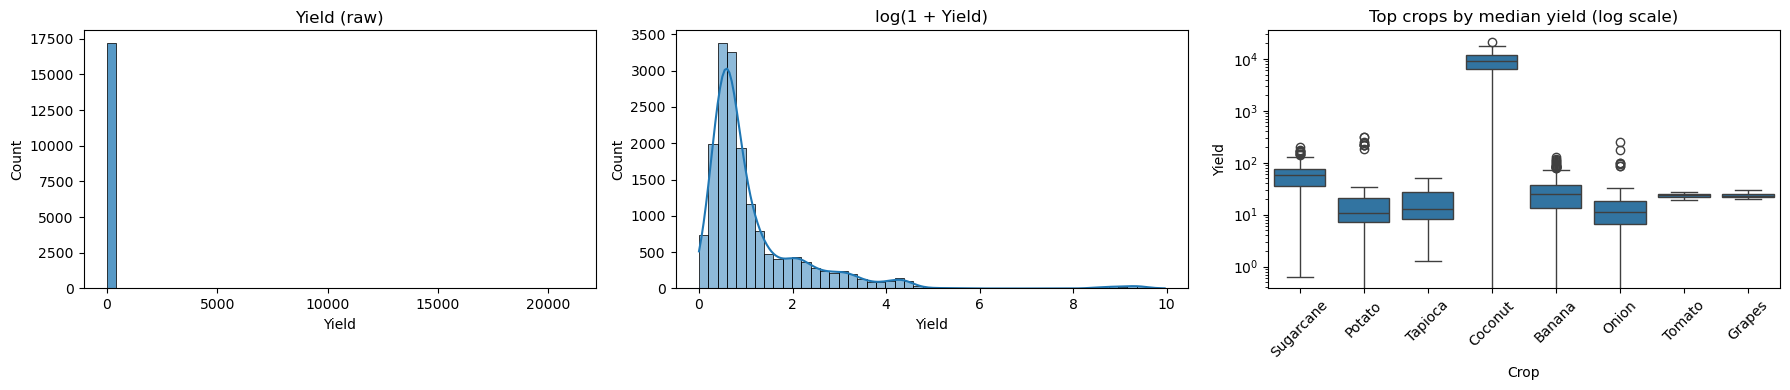

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Drop the leaky column right away
df = df.drop(columns=["Production"])

# Summary stats and skewness of the target
print("=== YIELD SUMMARY ===")
print(df["Yield"].describe(percentiles=[.5, .9, .99]).round(2))
print(f"\nSkewness (raw):      {df['Yield'].skew():.2f}")
print(f"Skewness (log1p):    {np.log1p(df['Yield']).skew():.2f}")

# IQR outlier count
q1, q3 = df["Yield"].quantile([.25, .75])
iqr = q3 - q1
n_out = (df["Yield"] > q3 + 1.5 * iqr).sum()
print(f"Outliers (IQR rule): {n_out} ({n_out / len(df) * 100:.1f}%)")

# Which crops have the highest median yield? (these explain the huge values)
print("\n=== MEDIAN YIELD BY CROP (top 8) ===")
print(df.groupby("Crop")["Yield"].median().sort_values(ascending=False).head(8).round(2))

# Plots: raw, log, boxplot of top crops
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df["Yield"], bins=50, ax=axes[0])
axes[0].set_title("Yield (raw)")
sns.histplot(np.log1p(df["Yield"]), bins=50, kde=True, ax=axes[1])
axes[1].set_title("log(1 + Yield)")
top = df.groupby("Crop")["Yield"].median().sort_values(ascending=False).head(8).index
sns.boxplot(data=df[df["Crop"].isin(top)], x="Crop", y="Yield", ax=axes[2])
axes[2].set_yscale("log")
axes[2].tick_params(axis="x", rotation=45)
axes[2].set_title("Top crops by median yield (log scale)")
plt.tight_layout()
plt.show()

> **Inference: the target is extremely skewed and crop-driven**
>
> - **Skew:** Raw `Yield` skewness is 11.67; after `log(1 + Yield)` it is 3.32. Mean 96.9 against median 1.10 and a 99th percentile of 242.7 (maximum 21,105).
> - **Outliers:** The IQR rule flags 2,933 rows (16.9%) as outliers. That is far too many to be typos; they are mostly a crop-scale effect.
> - **Left panel:** Raw histogram: a single spike near zero, with the long tail invisible. A model trained on this would be driven by a few giant values.
> - **Middle panel:** After the log, a clear hill peaks near 0.6 (a yield of roughly 0.8), with shoulders around 2 to 4.5 from higher-yield crops and a small separate bump at 9 to 10.
> - **Right panel:** Log-scale boxplot: Coconut has a median of 9,102 while every other crop sits between about 10 and 60 (Sugarcane 58.6, Banana 25.4, Tomato 23.5, Grapes 23.3). Tomato and Grapes boxes are very narrow because they have only 21 and 19 rows.

> **Decision: model `log(1 + Yield)` and keep `Crop` as a feature**
>
> - A log turns multiplicative differences into additive ones, which suits linear models. `log1p` also handles zero yields safely. Coconut is examined separately next.

Coconut rows: 179 (1.0% of data)

Yield WITHOUT coconut:
count    17221.00
mean         5.29
std         14.79
min          0.00
50%          1.09
99%         77.81
max        338.55
Name: Yield, dtype: float64
Skew raw / log1p without coconut: 7.11 / 1.76

Zero-yield rows by crop (top 5):
Crop
Jute                 9
Onion                6
Coconut              6
Horse-gram           4
Moong(Green Gram)    4
Name: count, dtype: int64

=== SKEWNESS OF INPUTS ===
                  raw  log1p
Area             7.62  -0.32
Annual_Rainfall  1.78  -0.08
Fertilizer       9.07  -0.21
Pesticide        9.72  -0.17


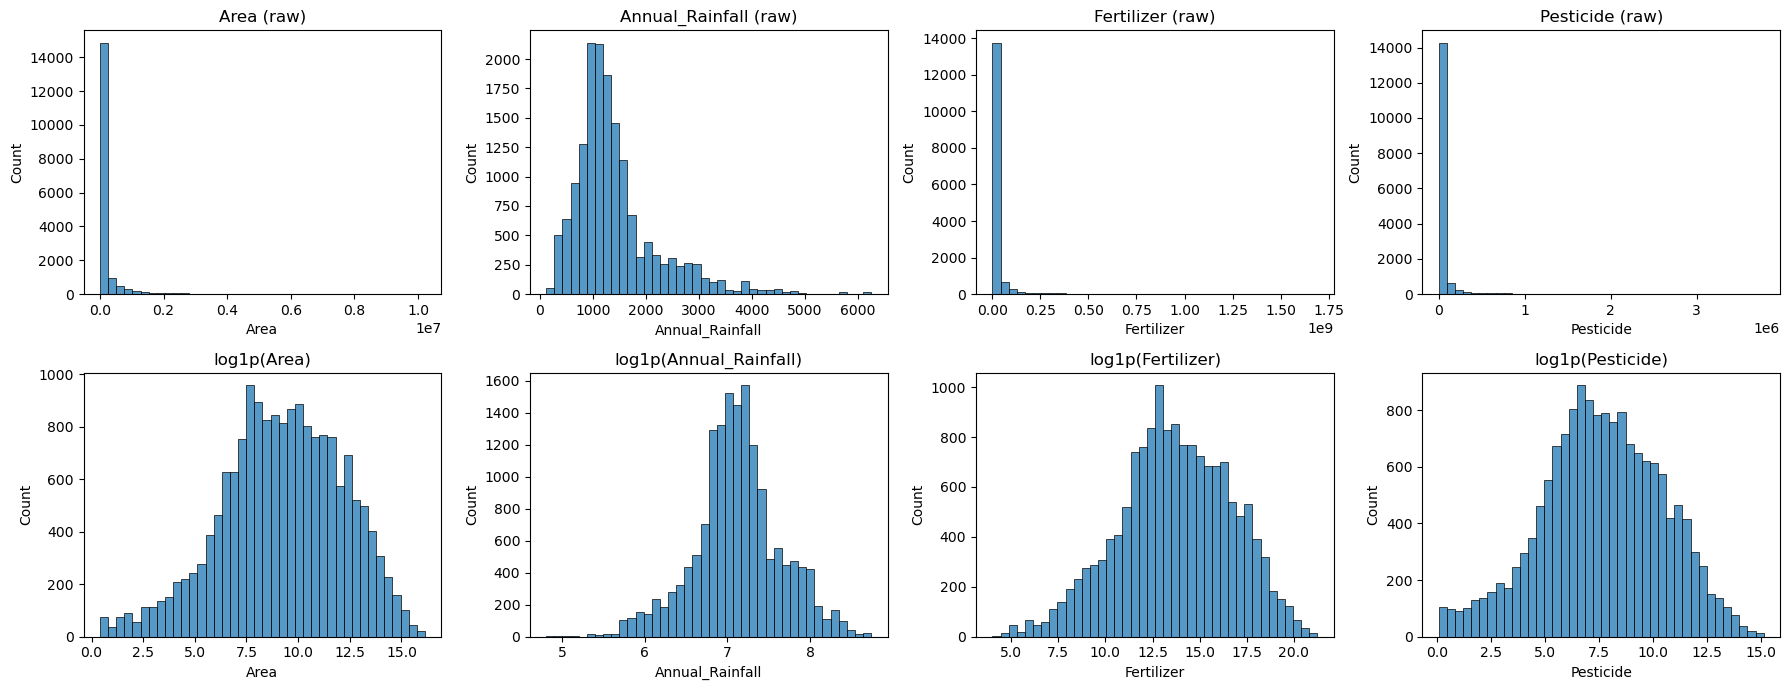

In [9]:
# 1) How much does Coconut distort things?
coco = df["Crop"] == "Coconut"
print("Coconut rows:", coco.sum(), f"({coco.mean() * 100:.1f}% of data)")
print("\nYield WITHOUT coconut:")
print(df.loc[~coco, "Yield"].describe(percentiles=[.5, .99]).round(2))
print(f"Skew raw / log1p without coconut: "
      f"{df.loc[~coco, 'Yield'].skew():.2f} / "
      f"{np.log1p(df.loc[~coco, 'Yield']).skew():.2f}")

# 2) Zero-yield rows: which crops?
print("\nZero-yield rows by crop (top 5):")
print(df[df["Yield"] == 0]["Crop"].value_counts().head())

# 3) Skewness of numeric inputs: raw vs log
num_in = ["Area", "Annual_Rainfall", "Fertilizer", "Pesticide"]
skew = pd.DataFrame({
    "raw": [df[c].skew() for c in num_in],
    "log1p": [np.log1p(df[c]).skew() for c in num_in],
}, index=num_in).round(2)
print("\n=== SKEWNESS OF INPUTS ===")
print(skew)

# 4) Histograms: raw (top) vs log (bottom)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, c in enumerate(num_in):
    sns.histplot(df[c].dropna(), bins=40, ax=axes[0, j])
    axes[0, j].set_title(f"{c} (raw)")
    sns.histplot(np.log1p(df[c].dropna()), bins=40, ax=axes[1, j])
    axes[1, j].set_title(f"log1p({c})")
plt.tight_layout()
plt.show()

> **Inference: Coconut is 1% of the rows but distorts every statistic**
>
> - **Impact:** Without Coconut the mean yield drops from 96.9 to 5.3, the standard deviation from 979 to 14.8 and the maximum from 21,105 to 338.6. Log skewness improves from 3.32 to 1.76.
> - **Probable cause:** Coconut is most likely recorded in a different unit (for example nuts rather than tonnes per hectare). This should be confirmed with the data source.
> - **Zero yields:** Only a few per crop (Jute 9, Onion 6, Coconut 6, Horse-gram 4, Moong 4; 77 in total). They may be genuine crop failures or unrecorded values; the data cannot tell which.
> - **Input skew (raw → log1p):** `Area` 7.62 → −0.32, `Annual_Rainfall` 1.78 → −0.08, `Fertilizer` 9.07 → −0.21, `Pesticide` 9.72 → −0.17.
> - **Charts:** Top row: `Area`, `Fertilizer` and `Pesticide` are one tall bar at zero, and rainfall has a right tail up to about 6,000. Bottom row: after the log all four become roughly bell-shaped.

> **Decision: keep Coconut, log-transform the inputs, and judge the model in two ways**
>
> - Coconut stays in the data and `Crop` gives it its own baseline level. `Area`, `Annual_Rainfall`, `Fertilizer` and `Pesticide` are all transformed with `log1p`.
> - Because a Coconut error in original units would dominate any RMSE, the model is judged mainly in log space and also in original units with Coconut excluded.

---

## Section 3: Exploratory Data Analysis
*How the inputs, crop, state, season and year relate to log yield.*

=== CORRELATION WITH log_Yield ===
log_Area               0.132
log_Pesticide          0.100
log_Fertilizer         0.067
Year                   0.050
log_Annual_Rainfall    0.017
Name: log_Yield, dtype: float64

=== INPUT-INPUT CORRELATION ===
                     log_Area  log_Annual_Rainfall  log_Fertilizer  \
log_Area                 1.00                -0.27            0.83   
log_Annual_Rainfall     -0.27                 1.00           -0.16   
log_Fertilizer           0.83                -0.16            1.00   
log_Pesticide            0.94                -0.22            0.96   
Year                    -0.06                 0.05           -0.01   

                     log_Pesticide  Year  
log_Area                      0.94 -0.06  
log_Annual_Rainfall          -0.22  0.05  
log_Fertilizer                0.96 -0.01  
log_Pesticide                 1.00 -0.01  
Year                         -0.01  1.00  


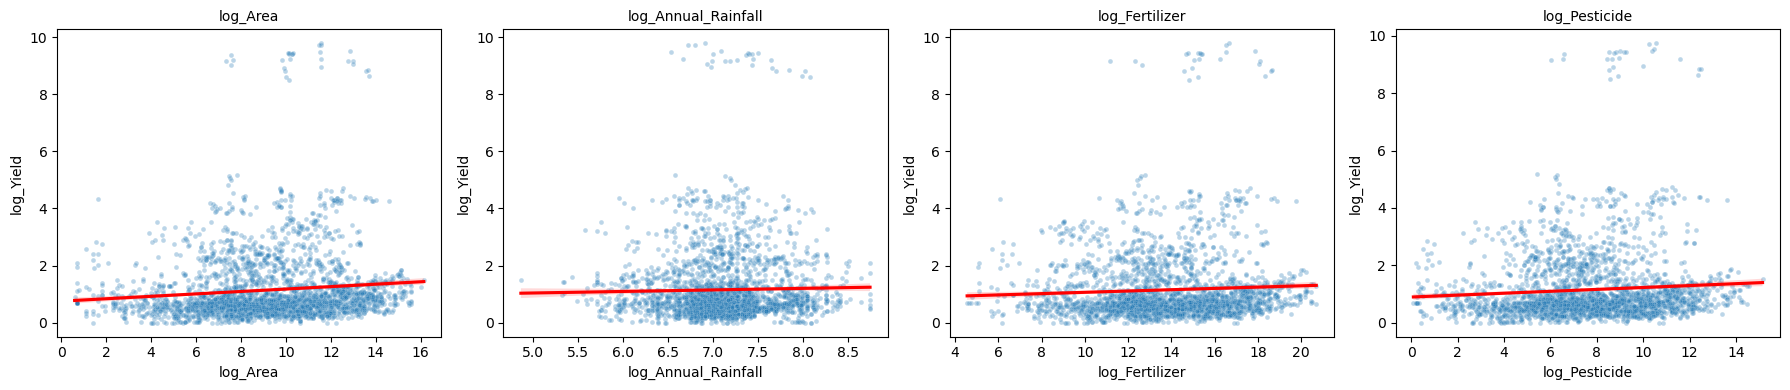

In [10]:
# Create log features (log1p = log(1 + x), safe for zeros)
df["log_Yield"] = np.log1p(df["Yield"])
for c in ["Area", "Annual_Rainfall", "Fertilizer", "Pesticide"]:
    df[f"log_{c}"] = np.log1p(df[c])

log_cols = ["log_Area", "log_Annual_Rainfall", "log_Fertilizer",
            "log_Pesticide", "Year"]

# Correlation of each feature with the log target
# (pairwise: blanks are ignored for now)
print("=== CORRELATION WITH log_Yield ===")
print(df[log_cols + ["log_Yield"]].corr()["log_Yield"]
      .drop("log_Yield").sort_values(ascending=False).round(3))

# Correlation between the inputs (to spot copies)
print("\n=== INPUT-INPUT CORRELATION ===")
print(df[log_cols].corr().round(2))

# Scatter plots against log_Yield (sample of 3,000 rows)
samp = df.sample(3000, random_state=42)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, log_cols):
    sns.scatterplot(data=samp, x=c, y="log_Yield", alpha=0.3, s=12, ax=ax)
    sns.regplot(data=samp, x=c, y="log_Yield", scatter=False,
                color="red", ax=ax)
    ax.set_title(c, fontsize=10)
plt.tight_layout()
plt.show()

> **Inference: every numeric input is a weak predictor on its own**
>
> - **Correlation with `log_Yield`:** `log_Area` 0.132, `log_Pesticide` 0.100, `log_Fertilizer` 0.067, `Year` 0.050, `log_Annual_Rainfall` 0.017. All are below 0.15.
> - **Scatter plots:** The red fit lines are almost flat. The clouds are wide, and a separate group at `log_Yield` 8.5 to 9.8 sits above every panel at all input values. Those points are Coconut: its level comes from crop identity, not from the inputs. (`Year` is not plotted; only four panels were drawn.)

> **Issue: three inputs are near-copies of each other**
>
> - **Evidence:** `log_Pesticide` with `log_Fertilizer` 0.96, `log_Area` with `log_Pesticide` 0.94, `log_Area` with `log_Fertilizer` 0.83.
> - **Consequence:** Using all three in a linear model gives unstable coefficients. Section 4 replaces them with per-area ratios.

### 3.2 Which categories explain yield?

=== VARIANCE EXPLAINED (eta squared) ===
Crop     0.830
State    0.051
Season   0.198

=== LOWEST 5 CROPS (median yield) ===
Crop
Cardamom               0.10
Niger seed             0.36
Sannhamp               0.40
Other Summer Pulses    0.43
Black pepper           0.45
Name: Yield, dtype: float64

=== HIGHEST 5 CROPS (median yield, excl. Coconut) ===
Crop
Tapioca      13.00
Grapes       23.29
Tomato       23.48
Banana       25.36
Sugarcane    58.61
Name: Yield, dtype: float64

=== MEDIAN YIELD BY SEASON ===
Season
Autumn         1.09
Kharif         0.98
Rabi           0.96
Summer         1.36
Whole Year     5.55
Winter        10.19
NaN            1.14
Name: Yield, dtype: float64


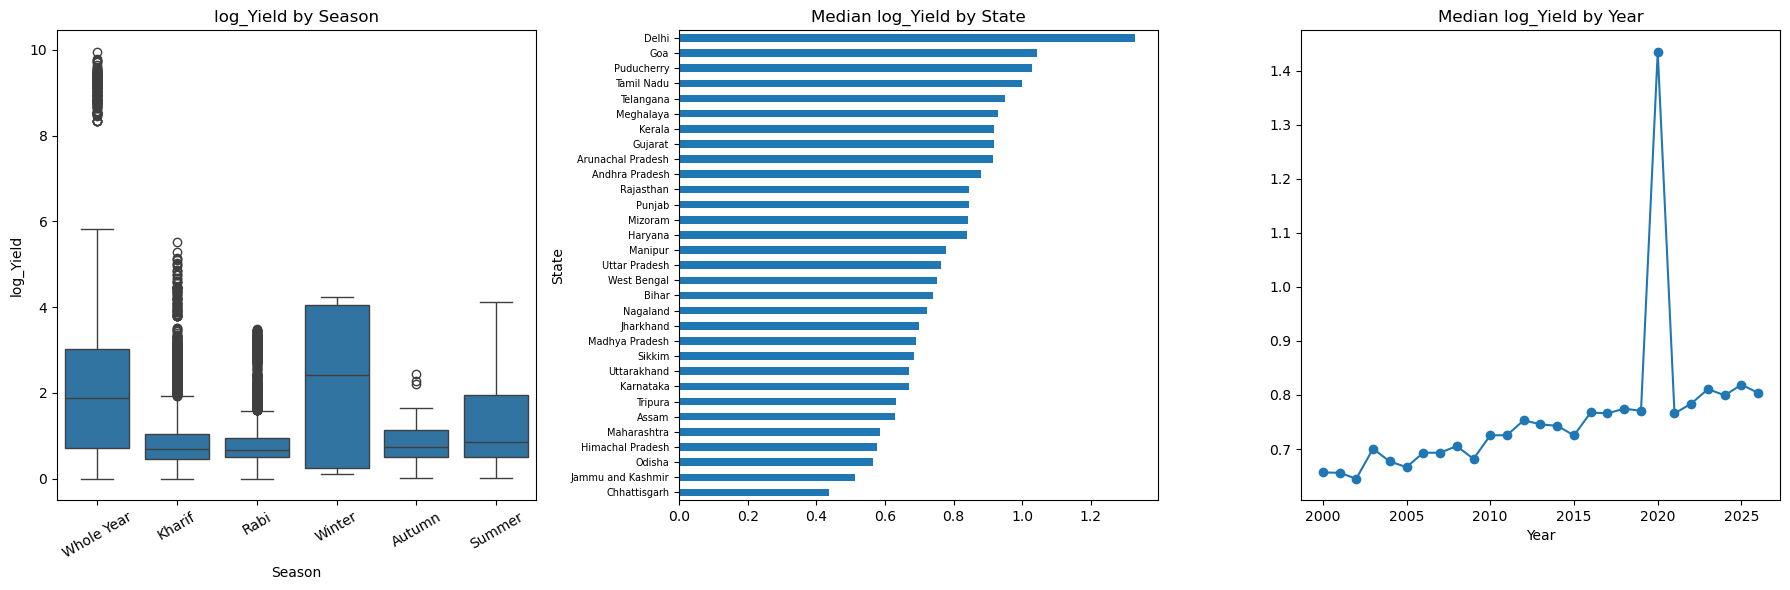

In [11]:
# How much variance of log_Yield does each category explain? (eta squared)
def eta_squared(data, cat, target="log_Yield"):
    d = data[[cat, target]].dropna()
    grand = d[target].mean()
    ss_between = d.groupby(cat)[target].apply(
        lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    ss_total = ((d[target] - grand) ** 2).sum()
    return ss_between / ss_total

print("=== VARIANCE EXPLAINED (eta squared) ===")
for c in ["Crop", "State", "Season"]:
    print(f"{c:8s} {eta_squared(df, c):.3f}")

# Median yield by crop: top 5 and bottom 5 (excluding Coconut)
med = (df[df["Crop"] != "Coconut"].groupby("Crop")["Yield"]
       .median().sort_values())
print("\n=== LOWEST 5 CROPS (median yield) ===")
print(med.head(5).round(2))
print("\n=== HIGHEST 5 CROPS (median yield, excl. Coconut) ===")
print(med.tail(5).round(2))

# Median yield by season and by year
print("\n=== MEDIAN YIELD BY SEASON ===")
print(df.groupby("Season", dropna=False)["Yield"].median().round(2))

# Charts: season boxplot, top/bottom states, yearly trend
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(data=df, x="Season", y="log_Yield", ax=axes[0])
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("log_Yield by Season")
st = df.groupby("State")["log_Yield"].median().sort_values()
st.plot(kind="barh", ax=axes[1], figsize=(18, 6))
axes[1].set_title("Median log_Yield by State")
axes[1].tick_params(axis="y", labelsize=7)
df.groupby("Year")["log_Yield"].median().plot(ax=axes[2], marker="o")
axes[2].set_title("Median log_Yield by Year")
plt.tight_layout()
plt.show()

> **Inference: crop explains most of the variation in yield**
>
> - **Variance explained (eta squared):** `Crop` 0.830, `Season` 0.198, `State` 0.051. Crop alone explains about 83% of the variance of log yield.
> - **Crop ladder (median yield):** Lowest: Cardamom 0.10, Niger seed 0.36, Sannhamp 0.40, Other Summer Pulses 0.43, Black pepper 0.45. Highest excluding Coconut: Sugarcane 58.6, Banana 25.4, Tomato 23.5, Grapes 23.3, Tapioca 13.0.
> - **Season:** Median yield is 10.2 for Winter and 5.6 for Whole Year but about 1 for Kharif, Rabi and Autumn. This is probably crop in disguise: long-duration crops such as sugarcane and banana are recorded as Whole Year. Winter has only 50 rows, so its wide box is unreliable. Blank `Season` has median 1.14, close to the common seasons, which supports filling it with the most frequent value.
> - **State chart:** Median log yield ranges from about 0.44 (Chhattisgarh) to 1.33 (Delhi). Delhi, Goa, Puducherry and Tamil Nadu are highest, which probably reflects the crop mix grown there rather than the state itself.
> - **Year chart:** A slow upward drift from about 0.65 in 2000 to 0.80 in 2026.

> **Issue: 2020 is a one-year spike**
>
> - **Evidence:** Median log yield jumps to 1.43 in 2020 against about 0.77 in 2019 and 2021. The EDA dashboard in Section 4 shows wheat, rice and maize all jumping in the same year, so it is not a single-crop effect.
> - **Cause:** Unknown. It could be a data artefact or a real event; it has not been investigated.
> - **Impact:** A straight-line `Year` term cannot represent a one-year spike; tree models can.

---

## Section 4: Feature Engineering
*Replace near-duplicate inputs with per-area intensity features, then review the full EDA picture.*

In [12]:
# Per-hectare intensity features (in log space, a ratio is a subtraction)
df["Fert_per_Area"] = df["log_Fertilizer"] - df["log_Area"]
df["Pest_per_Area"] = df["log_Pesticide"] - df["log_Area"]
df["Fert_per_Pest"] = df["log_Fertilizer"] - df["log_Pesticide"]

# Years since the start of the data (smaller numbers, same information)
df["Years_Since_2000"] = df["Year"] - 2000

# Blank handling check: new features inherit the blanks
new_feats = ["Fert_per_Area", "Pest_per_Area", "Fert_per_Pest",
             "Years_Since_2000"]
print("Missing values:\n", df[new_feats].isnull().sum())
print("\n", df[new_feats].describe().round(2).T)

# Overall correlation with log_Yield
base = ["log_Area", "log_Annual_Rainfall", "log_Fertilizer", "log_Pesticide"]
print("\n=== OVERALL CORRELATION WITH log_Yield ===")
print(df[base + new_feats + ["log_Yield"]].corr()["log_Yield"]
      .drop("log_Yield").sort_values(ascending=False).round(3))

# WITHIN-CROP correlation: subtract each crop's own average first
cols = base + new_feats + ["log_Yield"]
centered = df[cols] - df.groupby("Crop")[cols].transform("mean")
print("\n=== WITHIN-CROP CORRELATION WITH log_Yield ===")
print(centered.corr()["log_Yield"].drop("log_Yield")
      .sort_values(ascending=False).round(3))

Missing values:
 Fert_per_Area       2088
Pest_per_Area       1740
Fert_per_Pest       3594
Years_Since_2000       0
dtype: int64

                     count   mean   std   min   25%    50%    75%    max
Fert_per_Area     15312.0   4.46  1.74 -2.91  4.76   4.97   5.06   5.46
Pest_per_Area     15660.0  -1.57  1.03 -6.80 -1.51  -1.31  -1.11  -0.31
Fert_per_Pest     13806.0   6.04  0.83  1.78  6.03   6.18   6.32   7.37
Years_Since_2000  17400.0  13.59  7.88  0.00  7.00  14.00  21.00  26.00

=== OVERALL CORRELATION WITH log_Yield ===
log_Area               0.132
log_Pesticide          0.100
log_Fertilizer         0.067
Years_Since_2000       0.050
log_Annual_Rainfall    0.017
Pest_per_Area         -0.107
Fert_per_Pest         -0.108
Fert_per_Area         -0.112
Name: log_Yield, dtype: float64

=== WITHIN-CROP CORRELATION WITH log_Yield ===
log_Area               0.198
log_Pesticide          0.181
Years_Since_2000       0.158
log_Fertilizer         0.144
Pest_per_Area         -0.074
Fert_pe

> **Inference: fertilizer and pesticide are almost a fixed amount per unit of area**
>
> - **Features created:** `Fert_per_Area`, `Pest_per_Area`, `Fert_per_Pest` (differences of logs, so they are log ratios) and `Years_Since_2000`. Blanks carry through (2,088; 1,740; 3,594; 0).
> - **Surprise:** `Fert_per_Area` has median 4.97 and a middle-50% range of only 4.76 to 5.06, so nearly every row uses about e^5 ≈ 145 units of fertilizer per unit of area. `Pest_per_Area` is similarly tight (−1.51 to −1.11). Fertilizer and pesticide are essentially Area times a constant, which explains the 0.83 to 0.96 correlations in Section 3.
> - **Exceptions:** The mean of `Fert_per_Area` (4.46) is well below its median (4.97) and its minimum is −2.91, so a minority of rows have much lower fertilizer per unit of area. The dashboard below shows them as a detached group.
> - **Overall correlation with `log_Yield`:** The three ratios are weakly negative (−0.107 to −0.112).
> - **Within-crop correlation:** After subtracting each crop's own average, the signals sharpen: `log_Area` 0.198 (from 0.132), `log_Pesticide` 0.181, `Years_Since_2000` 0.158 (from 0.050), `log_Fertilizer` 0.144. Rainfall flips sign from +0.017 to −0.134. The crop mix was hiding within-crop relationships. The negative rainfall sign is weak and probably confounded with state and crop.

> **Decision: final feature set for the linear model**
>
> - **Numeric:** `log_Area`, `log_Annual_Rainfall`, `Fert_per_Area`, `Pest_per_Area`, `Years_Since_2000`
> - **Categorical:** `Crop`, `State`, `Season`
> - **Dropped:** `log_Fertilizer` and `log_Pesticide` (collinear with area) and `Fert_per_Pest` (exactly `Fert_per_Area − Pest_per_Area`, and 20.7% blank).

### 4.2 Consolidated EDA dashboard
*Six views of the full dataset (before any split; used for exploration only).*

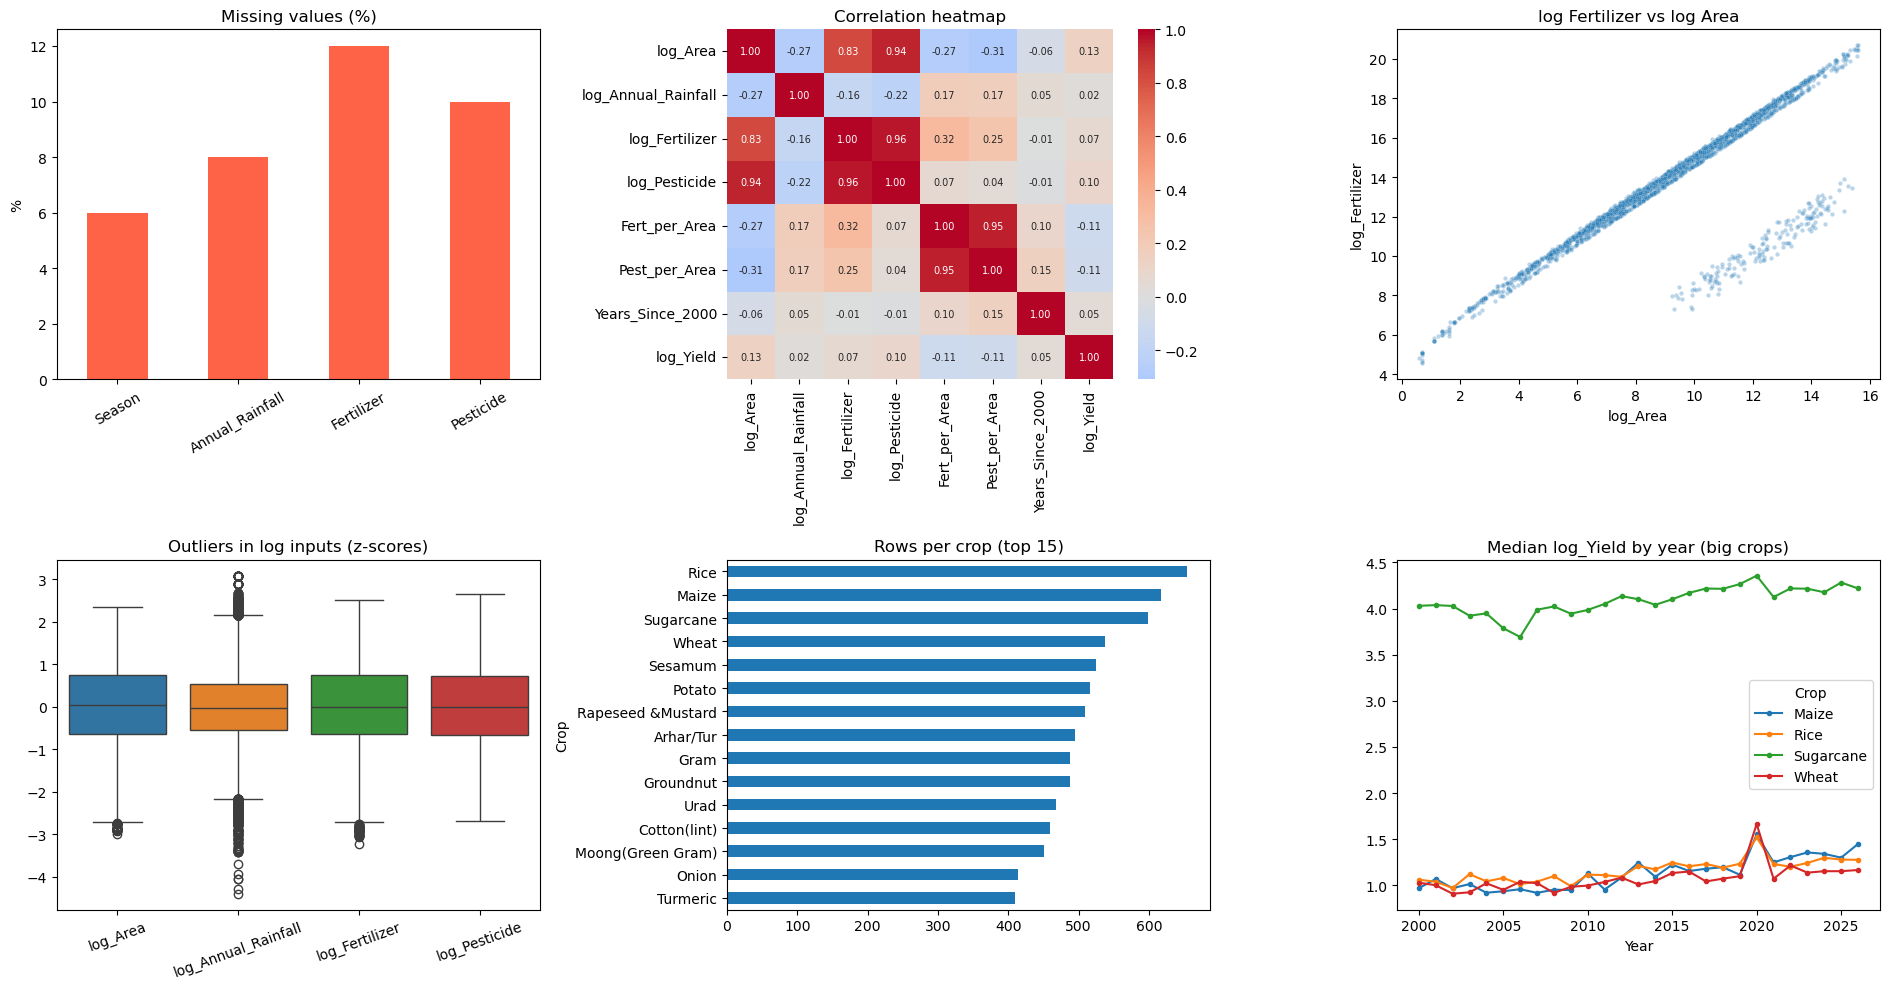

=== MEAN log_Yield: blank vs not blank ===
Season           present: 1.168   missing: 1.19
Annual_Rainfall  present: 1.169   missing: 1.174
Fertilizer       present: 1.176   missing: 1.117
Pesticide        present: 1.171   missing: 1.153

=== OUTLIERS (IQR rule) in log inputs ===
log_Area               112 (0.6%)
log_Annual_Rainfall    776 (4.5%)
log_Fertilizer          67 (0.4%)
log_Pesticide            0 (0.0%)


In [27]:
# Use the full df (before any split) for EDA only
fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# 1) Missing % per column
miss = (df[["Season", "Annual_Rainfall", "Fertilizer", "Pesticide"]]
        .isnull().mean() * 100)
miss.plot(kind="bar", ax=axes[0, 0], color="tomato")
axes[0, 0].set_title("Missing values (%)")
axes[0, 0].set_ylabel("%")
axes[0, 0].tick_params(axis="x", rotation=30)

# 2) Correlation heatmap (numeric features + log target)
cols = ["log_Area", "log_Annual_Rainfall", "log_Fertilizer", "log_Pesticide",
        "Fert_per_Area", "Pest_per_Area", "Years_Since_2000", "log_Yield"]
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7}, ax=axes[0, 1])
axes[0, 1].set_title("Correlation heatmap")

# 3) Fertilizer vs Area (log-log): shows the 'constant per hectare' pattern
samp = df.sample(3000, random_state=42)
sns.scatterplot(data=samp, x="log_Area", y="log_Fertilizer", alpha=0.3,
                s=10, ax=axes[0, 2])
axes[0, 2].set_title("log Fertilizer vs log Area")

# 4) Outlier boxplots for the log inputs (standardised so they share a scale)
z = df[["log_Area", "log_Annual_Rainfall", "log_Fertilizer", "log_Pesticide"]]
z = (z - z.mean()) / z.std()
sns.boxplot(data=z, ax=axes[1, 0])
axes[1, 0].set_title("Outliers in log inputs (z-scores)")
axes[1, 0].tick_params(axis="x", rotation=20)

# 5) Top 15 crops by number of rows
df["Crop"].value_counts().head(15).iloc[::-1].plot(kind="barh", ax=axes[1, 1])
axes[1, 1].set_title("Rows per crop (top 15)")

# 6) Median log_Yield trend over time for 4 big crops
big = ["Rice", "Wheat", "Maize", "Sugarcane"]
trend = (df[df["Crop"].isin(big)].groupby(["Year", "Crop"])["log_Yield"]
         .median().unstack())
trend.plot(ax=axes[1, 2], marker="o", markersize=3)
axes[1, 2].set_title("Median log_Yield by year (big crops)")
plt.tight_layout()
plt.show()

# Is missingness random? Compare mean yield of rows with vs without blanks
print("=== MEAN log_Yield: blank vs not blank ===")
for c in ["Season", "Annual_Rainfall", "Fertilizer", "Pesticide"]:
    g = df.groupby(df[c].isnull())["log_Yield"].mean().round(3)
    print(f"{c:16s} present: {g[False]}   missing: {g[True]}")

# Outlier counts (IQR) for the log inputs
print("\n=== OUTLIERS (IQR rule) in log inputs ===")
for c in ["log_Area", "log_Annual_Rainfall", "log_Fertilizer", "log_Pesticide"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    n = ((df[c] < q1 - 1.5 * i) | (df[c] > q3 + 1.5 * i)).sum()
    print(f"{c:20s} {n:5d} ({n / len(df) * 100:.1f}%)")

> **Inference: dashboard summary**
>
> - **Missing values (top left):** Bars sit at exactly 6, 8, 12 and 10 percent.
> - **Correlation heatmap (top middle):** Confirms the near-copies: `log_Fertilizer` with `log_Pesticide` 0.96, `log_Area` with `log_Pesticide` 0.94. The two ratio features are also still 0.95 correlated with each other. Everything correlates only −0.11 to +0.13 with `log_Yield`, and `Year` is close to 0 with everything.
> - **Fertilizer vs Area (top right):** A razor-thin straight line: fertilizer is a constant multiple of area. A small detached group sits several log units below the line at `log_Area` 9 to 14.5, rows with far less fertilizer per unit of area (roughly 50 to 100 times lower). Their cause has not been identified.
> - **Outlier boxplots (bottom left):** Rainfall has the most outliers, in both tails (z-scores down to about −4.4 and up to 3.1). IQR counts: `log_Annual_Rainfall` 776 (4.5%), `log_Area` 112 (0.6%), `log_Fertilizer` 67 (0.4%), `log_Pesticide` 0.
> - **Rows per crop (bottom middle):** The 15 largest crops each have at least about 410 rows (Rice 654). Many tail crops have far fewer (Tomato 21, Grapes 19, Other Summer Pulses 17), so predictions for them are less reliable.
> - **Yield by year for big crops (bottom right):** Sugarcane sits near 4.0 to 4.3 while wheat, rice and maize sit near 1.0 to 1.3, all drifting upward. Wheat, rice and maize jump together in 2020 (up to about 1.65), confirming the 2020 spike is not a single-crop effect.

> **Inference: blank rows do not differ in yield**
>
> - **Mean `log_Yield`, present vs missing:** `Season` 1.168 vs 1.190, `Annual_Rainfall` 1.169 vs 1.174, `Fertilizer` 1.176 vs 1.117, `Pesticide` 1.171 vs 1.153.
> - **Meaning:** The largest gap is 0.059, about 0.05 of a standard deviation of `log_Yield` (about 1.23). Blanks do not seem related to yield, which supports simple median and most-frequent imputation. This checks only the link to the target; it does not prove the blanks are random.
> - **Outliers:** Log-input outliers are few (0 to 4.5%). They are real values rather than typos, so none are removed.

> **Decision: EDA summary and what carries forward**
>
> - **Leakage:** `Production` dropped.
> - **Target:** Model `log(1 + Yield)`; keep Coconut and judge it separately.
> - **Drivers:** `Crop` (eta squared 0.83) far ahead of `Season` (0.20) and `State` (0.05). Individually, numeric inputs are weak, with `Area` the strongest.
> - **Inputs:** Fertilizer and pesticide are close to a constant per unit of area, so they are represented as per-area ratios.
> - **Data quality to remember:** Noisy `Yield` vs `Production / Area`, the 2020 spike, the Coconut scale, and a detached group with low fertilizer per unit of area.

---

## Section 5: Train-Test Split & Preprocessing
*Split first, then impute, scale and encode using training data only.*

In [13]:
from sklearn.model_selection import train_test_split

# Final feature list for the linear model (independent pieces only)
num_feats = ["log_Area", "log_Annual_Rainfall", "Fert_per_Area",
             "Pest_per_Area", "Years_Since_2000"]
cat_feats = ["Crop", "State", "Season"]

X = df[num_feats + cat_feats]
y = df["log_Yield"]          # target = log of yield
y_raw = df["Yield"]          # original units, kept for later checks

# 80% train, 20% test (random_state makes it repeatable)
X_train, X_test, y_train, y_test, yraw_train, yraw_test = train_test_split(
    X, y, y_raw, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

# Both sets should look alike
print("\nTrain log_Yield mean/std:", round(y_train.mean(), 3), round(y_train.std(), 3))
print("Test  log_Yield mean/std:", round(y_test.mean(), 3), round(y_test.std(), 3))

# Coconut should appear in both sets
print("\nCoconut rows -> train:", (X_train["Crop"] == "Coconut").sum(),
      "| test:", (X_test["Crop"] == "Coconut").sum())

# Any crop in test that never appears in train? (a risk for one-hot encoding)
unseen = set(X_test["Crop"]) - set(X_train["Crop"])
print("Crops only in test:", unseen if unseen else "none")

X_train: (13920, 8) | X_test: (3480, 8)

Train log_Yield mean/std: 1.174 1.231
Test  log_Yield mean/std: 1.149 1.21

Coconut rows -> train: 146 | test: 33
Crops only in test: none


> **Inference: the split is fair**
>
> - **Sizes:** 13,920 training rows and 3,480 test rows; 8 features (5 numeric, 3 categorical).
> - **Balance:** `log_Yield` mean/std is 1.174 / 1.231 (train) vs 1.149 / 1.210 (test).
> - **Rare crops:** Coconut has 146 rows in train and 33 in test, and no crop appears only in test, so one-hot encoding is safe.
> - **Why split first:** Imputing or scaling before the split would leak test information into training.

> **Issue: the split is random, not time-based**
>
> - Rows from the same crop, state and year appear on both sides, so the test score answers "how well can we predict a record like those we have seen". It is optimistic for forecasting future years. Section 12 lists a time-based split as a next step.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Recipe for numbers: fill blanks (median) -> scale
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Recipe for text: fill blanks (most common) -> one-hot (drop first avoids duplicates)
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                             sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_feats),
    ("cat", cat_pipe, cat_feats),
])

# Learn from TRAIN only, then apply to both
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

# Sanity checks
print("Train shape after:", X_train_p.shape)
print("Test shape after: ", X_test_p.shape)
print("NaNs in train/test:", np.isnan(X_train_p).sum(), np.isnan(X_test_p).sum())
print("\nFirst 6 columns:", list(feature_names[:6]))
print("Last 4 columns: ", list(feature_names[-4:]))

# Scaled numeric columns should have mean ~0 and std ~1 on TRAIN
print("\nMean of the 5 numeric cols:", X_train_p[:, :5].mean(axis=0).round(3))
print("Std of the 5 numeric cols: ", X_train_p[:, :5].std(axis=0).round(3))

Train shape after: (13920, 101)
Test shape after:  (3480, 101)
NaNs in train/test: 0 0

First 6 columns: ['num__log_Area', 'num__log_Annual_Rainfall', 'num__Fert_per_Area', 'num__Pest_per_Area', 'num__Years_Since_2000', 'cat__Crop_Arhar/Tur']
Last 4 columns:  ['cat__Season_Rabi', 'cat__Season_Summer', 'cat__Season_Whole Year', 'cat__Season_Winter']

Mean of the 5 numeric cols: [ 0.  0.  0. -0. -0.]
Std of the 5 numeric cols:  [1. 1. 1. 1. 1.]


> **Inference: pipeline works with no leakage**
>
> - **Recipe:** Numbers: median fill, then standardise. Text: most-frequent fill, then one-hot encoding with the first category dropped.
> - **Width:** 5 numeric + 96 one-hot columns (61 crops, 30 states and 5 seasons after dropping one category from each) = 101 columns.
> - **Checks:** 0 missing values in train and test. The five scaled numeric columns have mean 0 and standard deviation 1 on the training set.
> - **Fit rule:** Everything is fitted on training rows only, then applied to test.
> - **Blank `Season`:** Filled with the most common value (Kharif).

---

## Section 6: Baseline Linear Regression & Diagnostics
*Fit the baseline, then test its assumptions: equal spread, normality, independence, multicollinearity.*

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

lr = LinearRegression().fit(X_train_p, y_train)
pred_train = lr.predict(X_train_p)
pred_test = lr.predict(X_test_p)

# Helper that returns all four scores
def evaluate(y_true, y_pred, n_features):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {"R2": r2, "Adj_R2": adj, "RMSE": rmse, "MAE": mae}

k = X_train_p.shape[1]

# 1) Log space (what the model learned)
res_log = pd.DataFrame({
    "Train": evaluate(y_train, pred_train, k),
    "Test": evaluate(y_test, pred_test, k),
}).round(3)
print("=== BASELINE LINEAR REGRESSION (log space) ===")
print(res_log)

# 2) Original units: convert predictions back with exp(x) - 1
back_test = np.expm1(pred_test)
print("\n=== TEST, ORIGINAL UNITS (all crops) ===")
print(pd.Series(evaluate(yraw_test, back_test, k)).round(3))

# 3) Original units without Coconut
nc = (X_test["Crop"] != "Coconut").values
print("\n=== TEST, ORIGINAL UNITS (without Coconut) ===")
print(pd.Series(evaluate(yraw_test[nc], back_test[nc], k)).round(3))

=== BASELINE LINEAR REGRESSION (log space) ===
        Train   Test
R2      0.864  0.864
Adj_R2  0.863  0.860
RMSE    0.454  0.445
MAE     0.279  0.288

=== TEST, ORIGINAL UNITS (all crops) ===
R2          0.713
Adj_R2      0.704
RMSE      546.564
MAE        45.839
dtype: float64

=== TEST, ORIGINAL UNITS (without Coconut) ===
R2        0.694
Adj_R2    0.685
RMSE      7.847
MAE       2.293
dtype: float64


> **Inference: a solid baseline in log space, weaker in original units**
>
> - **Log space:** Test R² 0.864 (train 0.864), Adj R² 0.860, RMSE 0.445, MAE 0.288. Train and test are almost identical, so there is no overfitting.
> - **Error size:** A log MAE of 0.288 is a multiplicative miss of about e^0.288 ≈ 1.33, so a typical prediction is off by roughly a third (for example 3.0 predicted when the truth is about 2.3 or 4.0).
> - **Original units, all crops:** R² 0.713, RMSE 546.6, MAE 45.8. Coconut inflates these.
> - **Original units, without Coconut:** R² 0.694, RMSE 7.85, MAE 2.29.
> - **How much is the crop?:** A crop-only model would score about 0.83 (the eta squared from Section 3), so roughly 0.03 of the 0.864 comes from all the other features together.
> - **Back-transform:** `expm1` of a log-space prediction estimates a typical (median-like) yield rather than the mean, so a small downward bias in original units is expected.

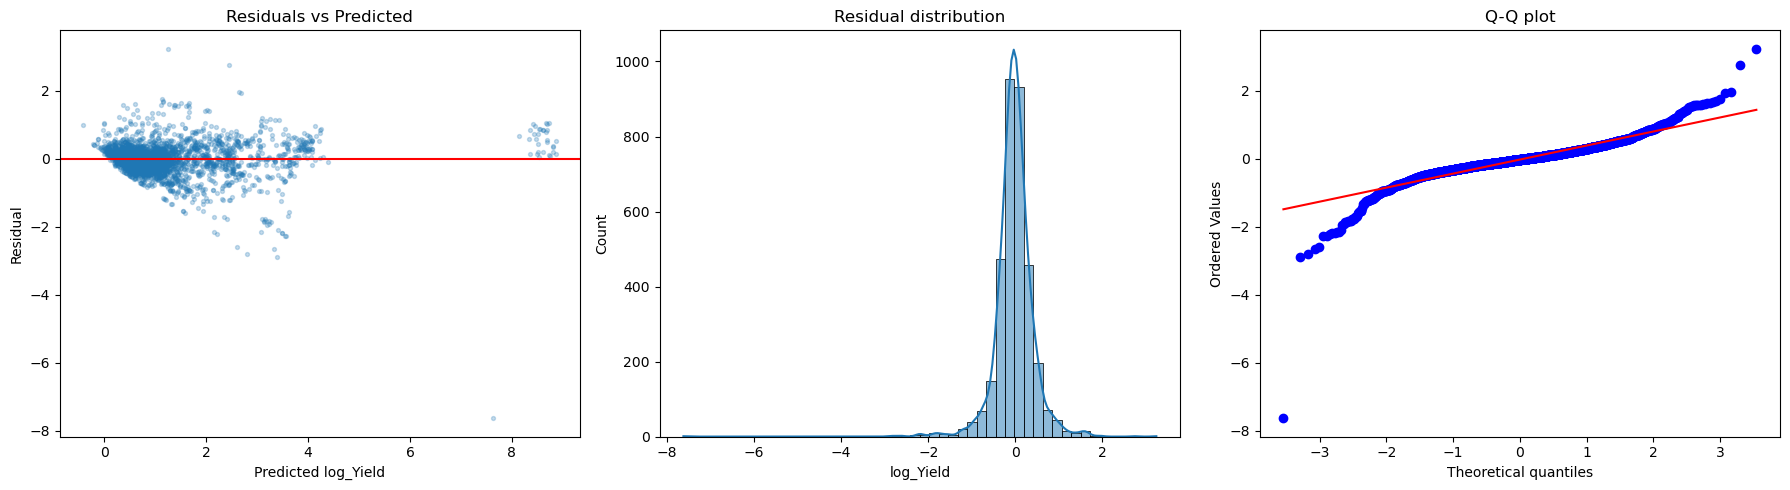

Mean residual: -0.018  (should be near 0)
Skewness: -1.70  (0 = symmetric)
Kurtosis: 29.95  (0 = normal tails)

=== CROPS WITH LARGEST AVERAGE MISS (log units) ===
                mean  count
Crop                       
Coconut         0.79     33
Jute            0.65     37
Ginger          0.63     63
other oilseeds  0.62     25
Sugarcane       0.62    133
Onion           0.60     69
Banana          0.57     53
Mesta           0.56     39

=== CROPS WITH SMALLEST AVERAGE MISS ===
               mean  count
Crop                      
Horse-gram     0.13     63
Niger seed     0.13     39
Small millets  0.11     85
Lentil         0.08     10
Moong          0.08     13


In [16]:
import scipy.stats as stats

resid = y_test - pred_test   # test-set residuals (log space)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(pred_test, resid, alpha=0.25, s=8)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted log_Yield"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")
sns.histplot(resid, bins=50, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot")
plt.tight_layout()
plt.show()

print(f"Mean residual: {resid.mean():.3f}  (should be near 0)")
print(f"Skewness: {stats.skew(resid):.2f}  (0 = symmetric)")
print(f"Kurtosis: {stats.kurtosis(resid):.2f}  (0 = normal tails)")

# Which crops have the largest average miss on the test set?
err = pd.DataFrame({"Crop": X_test["Crop"].values,
                    "abs_err": np.abs(resid.values)})
by_crop = (err.groupby("Crop")["abs_err"].agg(["mean", "count"])
           .query("count >= 10").sort_values("mean", ascending=False))
print("\n=== CROPS WITH LARGEST AVERAGE MISS (log units) ===")
print(by_crop.head(8).round(2))
print("\n=== CROPS WITH SMALLEST AVERAGE MISS ===")
print(by_crop.tail(5).round(2))

> **Issue: residual plots show broken assumptions**
>
> - **Mean residual:** −0.018, so there is no overall bias.
> - **Residuals vs predicted (left):** The main cloud is flat around zero, which is good, but the spread widens for predictions above about 2, so those are less reliable. A diagonal edge on the lower left appears because log yield cannot go below 0. A separate cluster at predicted 8 to 9 is Coconut. A lone dot near −7.6 is one Coconut row with zero yield that the model predicted as huge.
> - **Histogram (middle):** A tall, narrow peak with thin but very long tails: most predictions are close and a few are very wrong.
> - **Q-Q plot (right):** Points follow the line in the middle and peel away at both ends; the lone point at the bottom is far off. Skewness −1.70 and excess kurtosis 29.95 confirm heavy tails.

> **Inference: the model predicts "plain" crops well and struggles with high-yield, high-variation ones**
>
> - **Largest average miss (log units, crops with at least 10 test rows):** Coconut 0.79, Jute 0.65, Ginger 0.63, other oilseeds 0.62, Sugarcane 0.62, Onion 0.60, Banana 0.57, Mesta 0.56.
> - **Smallest:** Horse-gram 0.13, Niger seed 0.13, Small millets 0.11, Lentil 0.08, Moong 0.08. Lentil and Moong have only 10 and 13 test rows, so treat those two as indicative.
> - **Meaning:** The hardest crops miss by 5 to 10 times more than the easiest ones.

In [17]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

resid_train = y_train.values - pred_train
X_sm = sm.add_constant(X_train_p)

bp_p = het_breuschpagan(resid_train, X_sm)[1]
jb_p = stats.jarque_bera(resid_train)[1]
print(f"Breusch-Pagan p-value: {bp_p:.4g}  (p<0.05 -> unequal spread)")
print(f"Jarque-Bera p-value:   {jb_p:.4g}  (p<0.05 -> not normal)")
print(f"Durbin-Watson:         {durbin_watson(resid_train):.2f}  (about 2 = fine)")

# VIF for the 5 numeric features (fit with the numeric block only)
num_block = X_train_p[:, :5]
vif_num = pd.Series(
    [variance_inflation_factor(num_block, i) for i in range(5)],
    index=num_feats).round(2)
print("\n=== VIF (numeric features) ===")
print(vif_num)

# Worst 8 test rows (largest absolute residual), in readable form
worst = X_test.copy()
worst["actual_Yield"] = yraw_test.values
worst["pred_Yield"] = np.expm1(pred_test).round(2)
worst["resid"] = resid.values.round(2)
print("\n=== 8 WORST TEST ROWS ===")
print(worst.reindex(worst["resid"].abs().sort_values(ascending=False).index)
      .head(8)[["Crop", "State", "Season", "actual_Yield",
                "pred_Yield", "resid"]].to_string())

# How many zero-yield rows exist in train vs test?
print("\nZero-yield rows -> train:", (yraw_train == 0).sum(),
      "| test:", (yraw_test == 0).sum())

Breusch-Pagan p-value: 8.342e-232  (p<0.05 -> unequal spread)
Jarque-Bera p-value:   0  (p<0.05 -> not normal)
Durbin-Watson:         2.00  (about 2 = fine)

=== VIF (numeric features) ===
log_Area               1.15
log_Annual_Rainfall    1.08
Fert_per_Area          3.37
Pest_per_Area          3.48
Years_Since_2000       1.03
dtype: float64

=== 8 WORST TEST ROWS ===
                 Crop              State      Season  actual_Yield  pred_Yield  resid
3073          Coconut       Chhattisgarh  Whole Year      0.000000     2048.68  -7.63
15075  other oilseeds          Telangana      Kharif     87.345649        2.46   3.24
14757       Sugarcane  Jammu and Kashmir      Kharif      0.634646       28.37  -2.89
8952           Banana            Haryana  Whole Year      0.000000       15.30  -2.79
10943           Onion            Haryana  Whole Year    178.653077       10.46   2.75
17191       Sugarcane  Jammu and Kashmir      Kharif      0.991868       27.06  -2.65
4767           Potato      

> **Issue: formal tests confirm the plots**
>
> - **Breusch-Pagan:** p ≈ 8e-232: unequal spread is real.
> - **Jarque-Bera:** p ≈ 0: residuals are not normal.
> - **Durbin-Watson:** 2.00, which looks fine, but this file is shuffled (years appear in random order), so the test has little meaning here.
> - **VIF (numeric features):** `log_Area` 1.15, `log_Annual_Rainfall` 1.08, `Fert_per_Area` 3.37, `Pest_per_Area` 3.48, `Years_Since_2000` 1.03, all below 5. VIF is measured after median imputation of 10 to 12% of rows, which probably hides the 0.95 correlation seen between the two ratio features in the dashboard.
> - **Consequence:** Predictions are usable, but the OLS coefficients, p-values and confidence intervals are not reliable. The linear model is treated as a baseline, not as a tool for statistical inference.

> **Inference: the eight worst test rows are unusual records, not systematic errors**
>
> - **Over-predicted (actual far below the crop's norm):** Coconut (Chhattisgarh) actual 0.0 vs predicted 2,049; Sugarcane (Jammu and Kashmir) 0.63 vs 28.4 and 0.99 vs 27.1; Banana (Haryana) 0.0 vs 15.3; Potato (Telangana) 0.01 vs 12.6; Sugarcane (Meghalaya) 2.68 vs 34.1.
> - **Under-predicted (actual far above the norm):** other oilseeds (Telangana) 87.3 vs 2.5; Onion (Haryana) 178.7 vs 10.5.
> - **Zero yields:** 62 in train and 15 in test (77 in total).
> - **Meaning:** These are rows where the recorded yield is wildly out of line for the crop. They could be crop failures or recording errors; the next step checks the labels.

In [19]:
# Reload the raw file to get Production back (same row order as df)
raw = pd.read_csv(r"C:\Users\nazmi\Downloads\india_crop_yield_train_missing.csv",
                  usecols=["Area", "Production", "Yield"])

# Ratio of the recorded Yield to the "calculated" Production / Area
calc = raw["Production"] / raw["Area"]
ratio = (raw["Yield"] / calc).replace([np.inf, -np.inf], np.nan)
gap = (ratio - 1).abs()       # 0 = perfectly consistent

# Bucket the rows by how much they disagree
bins = pd.cut(gap, [-0.001, 0.01, 0.05, 0.20, np.inf],
              labels=["<1% off", "1-5% off", "5-20% off", ">20% off"])
print("=== LABEL CONSISTENCY (all rows) ===")
print(bins.value_counts(dropna=False).sort_index())

# Where do the 8 worst test rows fall?
worst_idx = (resid.abs().sort_values(ascending=False).head(8)).index
print("\n=== CONSISTENCY OF THE 8 WORST TEST ROWS ===")
print(pd.DataFrame({"Yield": raw.loc[worst_idx, "Yield"].round(2),
                    "Prod/Area": calc[worst_idx].round(2),
                    "bucket": bins[worst_idx]}))

# Model score on the test set, split by label consistency
tb = bins.loc[X_test.index]
print("\n=== TEST SCORE BY LABEL CONSISTENCY (log space) ===")
rows = []
for b in tb.cat.categories:
    m = (tb == b).values
    if m.sum() > 20:
        rows.append({"bucket": b, "n": int(m.sum()),
                     "R2": r2_score(y_test[m], pred_test[m]),
                     "MAE": mean_absolute_error(y_test[m], pred_test[m])})
print(pd.DataFrame(rows).round(3).to_string(index=False))

=== LABEL CONSISTENCY (all rows) ===
<1% off      8072
1-5% off     3424
5-20% off    4194
>20% off     1632
NaN            78
Name: count, dtype: int64

=== CONSISTENCY OF THE 8 WORST TEST ROWS ===
        Yield  Prod/Area    bucket
3073     0.00       0.00       NaN
15075   87.35      87.35   <1% off
14757    0.63       0.63   <1% off
8952     0.00       0.00       NaN
10943  178.65      15.01  >20% off
17191    0.99       0.99   <1% off
4767     0.01       0.01   <1% off
8470     2.68       2.68   <1% off

=== TEST SCORE BY LABEL CONSISTENCY (log space) ===
   bucket    n    R2   MAE
  <1% off 1603 0.868 0.298
 1-5% off  696 0.891 0.259
5-20% off  821 0.917 0.263
 >20% off  346 0.724 0.303


> **Inference: label inconsistency explains only part of the error**
>
> - **Consistency of `Yield` with `Production / Area`:** Under 1% off: 8,072 rows (46.4%); 1-5% off: 3,424 (19.7%); 5-20%: 4,194 (24.1%); over 20%: 1,632 (9.4%); undefined (zero production): 78. More than half the rows disagree by over 1%.
> - **Worst rows:** Five of the eight worst test rows are within 1%, so their labels are consistent and the model is simply wrong. Two are zero-yield rows. Only one (Onion, Haryana: Yield 178.65 vs Production / Area 15.01) has a clearly inconsistent label.
> - **Test score by bucket (log space):** Under 1%: R² 0.868, MAE 0.298 (n = 1,603). 1-5%: 0.891, 0.259 (696). 5-20%: 0.917, 0.263 (821). Over 20%: R² 0.724, MAE 0.303 (346).
> - **Reading:** R² drops for the most inconsistent rows, but MAE is nearly unchanged (0.30 vs 0.26 to 0.30), so noisy labels are a modest contributor to the error.

> **Decision: keep all rows and report the label noise**
>
> - There is no way to know whether `Yield` or `Production / Area` is the correct value, so no rows are filtered. The mismatch is documented as a data-quality limitation and should be raised with the data owner.

---

## Section 7: Regularised Models: Ridge & Lasso
*Check whether shrinking the coefficients helps.*

In [20]:
from sklearn.linear_model import RidgeCV, LassoCV

alphas = np.logspace(-4, 2, 40)

ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train_p, y_train)
lasso = LassoCV(alphas=alphas, cv=5, max_iter=20000,
                random_state=42).fit(X_train_p, y_train)

print(f"Best Ridge alpha: {ridge.alpha_:.4f}")
print(f"Best Lasso alpha: {lasso.alpha_:.4f}")

# Log-space test scores for all three linear models
scores = pd.DataFrame({
    "LinearReg": res_log["Test"],
    "Ridge": evaluate(y_test, ridge.predict(X_test_p), k),
    "Lasso": evaluate(y_test, lasso.predict(X_test_p), k),
}).round(3)
print("\n=== TEST SCORES (log space) ===")
print(scores)

# Original-unit R2 without Coconut for the same three
nc = (X_test["Crop"] != "Coconut").values
orig = {}
for name, m in [("LinearReg", lr), ("Ridge", ridge), ("Lasso", lasso)]:
    p = np.expm1(m.predict(X_test_p))
    orig[name] = r2_score(yraw_test[nc], p[nc])
print("\nTest R2 in original units (no Coconut):",
      {k_: round(v, 3) for k_, v in orig.items()})

# How many features did Lasso bench?
coefs = pd.DataFrame({"feature": feature_names, "Linear": lr.coef_,
                      "Ridge": ridge.coef_, "Lasso": lasso.coef_})
print(f"\nLasso zeroed-out features: {(coefs['Lasso'] == 0).sum()} of {k}")
print("\n=== TOP 10 FEATURES BY |Lasso coefficient| ===")
print(coefs.reindex(coefs["Lasso"].abs().sort_values(ascending=False).index)
      .head(10).round(2).to_string(index=False))

Best Ridge alpha: 0.1701
Best Lasso alpha: 0.0001

=== TEST SCORES (log space) ===
        LinearReg  Ridge  Lasso
R2          0.864  0.864  0.864
Adj_R2      0.860  0.860  0.860
RMSE        0.445  0.446  0.445
MAE         0.288  0.288  0.288

Test R2 in original units (no Coconut): {'LinearReg': 0.694, 'Ridge': 0.694, 'Lasso': 0.691}

Lasso zeroed-out features: 2 of 101

=== TOP 10 FEATURES BY |Lasso coefficient| ===
               feature  Linear  Ridge  Lasso
     cat__Crop_Coconut    7.33   7.31   7.47
   cat__Crop_Sugarcane    2.69   2.67   2.83
      cat__Crop_Grapes    2.16   2.12   2.21
      cat__Crop_Banana    2.05   2.04   2.20
      cat__Crop_Tomato    2.05   2.02   2.12
     cat__Crop_Tapioca    1.72   1.71   1.87
      cat__Crop_Potato    1.52   1.51   1.68
       cat__Crop_Onion    1.41   1.39   1.57
cat__Crop_Sweet potato    1.32   1.31   1.47
      cat__Crop_Ginger    0.94   0.93   1.09


> **Inference: regularisation changes nothing**
>
> - **Alphas:** Ridge 0.1701 and Lasso 0.0001. The Lasso value is the smallest alpha in the search grid, so cross-validation asked for essentially no penalty.
> - **Scores:** All three models: test R² 0.864, RMSE 0.445 to 0.446, MAE 0.288. In original units without Coconut: R² 0.694 (Linear), 0.694 (Ridge), 0.691 (Lasso).
> - **Lasso:** Set only 2 of 101 coefficients to zero.
> - **Why:** 13,920 rows for 101 features with no train-test gap leaves nothing to regularise.
> - **Top coefficients:** All ten largest are crop dummies: Coconut 7.33, Sugarcane 2.69, Grapes 2.16, Banana 2.05, Tomato 2.05, Tapioca 1.72, Potato 1.52, Onion 1.41, Sweet potato 1.32, Ginger 0.94 (Linear model, relative to the dropped reference crop). Coconut at +7.33 is on the order of a thousand times the reference level.
> - **Meaning:** Crop identity dominates, as the eta squared figure predicted. The linear family has reached its ceiling at R² 0.86 (log) and 0.69 (original units, no Coconut).

> **Decision: move to non-linear models**
>
> - A straight line cannot express crop-specific effects (for example, how area or rainfall matters differently for each crop). Tree models can.

---

## Section 8: Non-linear Models: Random Forest & XGBoost
*Can trees capture the crop-specific behaviour the linear model cannot?*

In [21]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                           n_jobs=-1, random_state=42)
rf.fit(X_train_p, y_train)

rf_pred_train = rf.predict(X_train_p)
rf_pred_test = rf.predict(X_test_p)

rf_res = pd.DataFrame({
    "Train": evaluate(y_train, rf_pred_train, k),
    "Test": evaluate(y_test, rf_pred_test, k),
}).round(3)
print("=== RANDOM FOREST (log space) ===")
print(rf_res)

# Original units without Coconut
nc = (X_test["Crop"] != "Coconut").values
rf_back = np.expm1(rf_pred_test)
print("\nTest R2 original units (no Coconut):",
      round(r2_score(yraw_test[nc], rf_back[nc]), 3))
print("Test MAE original units (no Coconut):",
      round(mean_absolute_error(yraw_test[nc], rf_back[nc]), 3))

# Comparison with the linear model
print("\n=== TEST COMPARISON (log space) ===")
print(pd.DataFrame({"LinearReg": res_log["Test"],
                    "RandomForest": rf_res["Test"]}))

# Residual shape
rf_resid = y_test - rf_pred_test
print(f"\nResidual skewness: {stats.skew(rf_resid):.2f} (linear: -1.70)")
print(f"Residual kurtosis: {stats.kurtosis(rf_resid):.2f} (linear: 29.95)")

=== RANDOM FOREST (log space) ===
        Train   Test
R2      0.991  0.967
Adj_R2  0.991  0.966
RMSE    0.116  0.219
MAE     0.059  0.123

Test R2 original units (no Coconut): 0.889
Test MAE original units (no Coconut): 0.961

=== TEST COMPARISON (log space) ===
        LinearReg  RandomForest
R2          0.864         0.967
Adj_R2      0.860         0.966
RMSE        0.445         0.219
MAE         0.288         0.123

Residual skewness: -0.64 (linear: -1.70)
Residual kurtosis: 32.51 (linear: 29.95)


> **Inference: Random Forest is a big improvement, with a visible overfit gap**
>
> - **Test:** R² 0.967, RMSE 0.219, MAE 0.123, against the linear 0.864, 0.445 and 0.288. RMSE is roughly halved.
> - **Overfit gap:** Train R² 0.991 vs test 0.967 (RMSE 0.116 vs 0.219). Generalisation is still good.
> - **Original units, without Coconut:** R² 0.889, MAE 0.961.
> - **Residual shape:** Skewness improves from −1.70 to −0.64, but excess kurtosis stays high (32.5 vs 29.95): a few unpredictable rows remain.
> - **Why it won:** Each tree can ask "which crop?" first and then "how much rain, or how large an area?" separately for each crop.

In [22]:
from xgboost import XGBRegressor

# Hold out part of TRAIN for early stopping (test set stays untouched)
Xtr, Xval, ytr, yval = train_test_split(
    X_train_p, y_train, test_size=0.15, random_state=42)

xgb = XGBRegressor(
    n_estimators=3000,         # max number of runners
    learning_rate=0.05,        # gentle corrections
    max_depth=6,               # deeper trees to learn crop x feature effects
    min_child_weight=3,        # a rule needs at least a few rows
    subsample=0.8,             # each tree sees 80% of rows
    colsample_bytree=0.8,      # and 80% of columns
    early_stopping_rounds=100, # stop when validation stops improving
    n_jobs=-1,
    random_state=42,
)
xgb.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
print("Trees actually used:", xgb.best_iteration + 1)

xgb_res = pd.DataFrame({
    "Train": evaluate(y_train, xgb.predict(X_train_p), k),
    "Test": evaluate(y_test, xgb.predict(X_test_p), k),
}).round(3)
print("\n=== XGBOOST (log space) ===")
print(xgb_res)

# Original units without Coconut
xgb_back = np.expm1(xgb.predict(X_test_p))
print("\nTest R2 original units (no Coconut):",
      round(r2_score(yraw_test[nc], xgb_back[nc]), 3))
print("Test MAE original units (no Coconut):",
      round(mean_absolute_error(yraw_test[nc], xgb_back[nc]), 3))

print("\n=== TEST COMPARISON (log space) ===")
print(pd.DataFrame({"LinearReg": res_log["Test"],
                    "RandomForest": rf_res["Test"],
                    "XGBoost": xgb_res["Test"]}))

Trees actually used: 2984

=== XGBOOST (log space) ===
        Train   Test
R2      0.992  0.970
Adj_R2  0.992  0.969
RMSE    0.109  0.208
MAE     0.057  0.124

Test R2 original units (no Coconut): 0.908
Test MAE original units (no Coconut): 0.986

=== TEST COMPARISON (log space) ===
        LinearReg  RandomForest  XGBoost
R2          0.864         0.967    0.970
Adj_R2      0.860         0.966    0.969
RMSE        0.445         0.219    0.208
MAE         0.288         0.123    0.124


> **Inference: XGBoost is slightly better than Random Forest**
>
> - **Test:** R² 0.970, RMSE 0.208, MAE 0.124. Train R² 0.992 (RMSE 0.109).
> - **Original units, without Coconut:** R² 0.908 (Random Forest 0.889) but MAE 0.986 (Random Forest 0.961).
> - **Reading:** XGBoost wins on R² and RMSE (it makes fewer big misses), while the typical miss is tied in log space (MAE 0.124 vs 0.123) and slightly worse in original units. The two models are close.
> - **Trees:** It used 2,984 of the 3,000 allowed, so early stopping barely triggered and it was still improving slowly.
> - **Training data:** It was fitted on 85% of the training rows; the other 15% were held out for early stopping.

In [23]:
configs = {
    "base (depth 6)":     dict(max_depth=6, min_child_weight=3),
    "shallow (depth 4)":  dict(max_depth=4, min_child_weight=3),
    "deeper (depth 8)":   dict(max_depth=8, min_child_weight=3),
    "regularised":        dict(max_depth=6, min_child_weight=5,
                               reg_lambda=10, reg_alpha=0.5),
}

rows, models = [], {}
for name, params in configs.items():
    m = XGBRegressor(n_estimators=4000, learning_rate=0.08,
                     subsample=0.8, colsample_bytree=0.8,
                     early_stopping_rounds=100, n_jobs=-1,
                     random_state=42, **params)
    m.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
    models[name] = m
    rmse = lambda X_, y_: np.sqrt(mean_squared_error(y_, m.predict(X_)))
    rows.append({"model": name, "trees": m.best_iteration + 1,
                 "Train_RMSE": rmse(Xtr, ytr), "Val_RMSE": rmse(Xval, yval),
                 "Test_RMSE": rmse(X_test_p, y_test)})

out = pd.DataFrame(rows).round(3)
out["Gap (Val-Train)"] = (out["Val_RMSE"] - out["Train_RMSE"]).round(3)
print(out.to_string(index=False))
print("\nBest by validation:", out.sort_values("Val_RMSE").iloc[0]["model"])

            model  trees  Train_RMSE  Val_RMSE  Test_RMSE  Gap (Val-Train)
   base (depth 6)   1965       0.060     0.243      0.213            0.183
shallow (depth 4)   2297       0.124     0.252      0.222            0.128
 deeper (depth 8)   1924       0.021     0.233      0.209            0.212
      regularised   2161       0.105     0.268      0.234            0.163

Best by validation: deeper (depth 8)


> **Inference: tuning: depth 8 wins on validation, and the test set agrees**
>
> - **Results (RMSE, log units):** Depth 6: train 0.060, validation 0.243, test 0.213. Depth 4: 0.124, 0.252, 0.222. Depth 8: 0.021, 0.233, 0.209. Regularised depth 6: 0.105, 0.268, 0.234.
> - **Winner:** Depth 8 has the lowest validation RMSE (0.233) and the lowest test RMSE (0.209), so the choice is not luck.
> - **Overfitting trade-off:** Depth 8 has train RMSE 0.021 (nearly memorised) and the biggest gap (0.212), but it still generalises best. The shallow model has the smallest gap (0.128) and a worse test score.
> - **Regularised:** Penalties and a higher `min_child_weight` hurt (validation 0.268), so the extra constraint costs more than it saves.
> - **Early stopping:** Triggered in every run (1,924 to 2,297 trees).

> **Issue: differences between configurations are small and come from one validation split**
>
> - Test RMSE ranges only from 0.209 to 0.234 and the top three are within 0.013 of each other. The validation set is a single 15% slice (2,088 rows), so the ranking has some noise. Cross-validated tuning would be more robust, but the conclusion that deeper trees are not harmful is stable.

---

## Section 9: Final Model & Feature Importance
*Score the winning XGBoost and measure what drives its predictions.*

=== FINAL XGBOOST (log space) ===
        Train   Test
R2      0.994  0.970
Adj_R2  0.994  0.969
RMSE    0.093  0.209
MAE     0.032  0.123

Test R2 original units, all crops:         0.966
Test R2 original units, without Coconut:   0.904

=== PERMUTATION IMPORTANCE (RMSE increase when shuffled) ===
Crop                   1.367
log_Area               0.273
State                  0.209
Season                 0.084
Years_Since_2000       0.071
log_Annual_Rainfall    0.032
Pest_per_Area          0.017
Fert_per_Area          0.013
dtype: float64


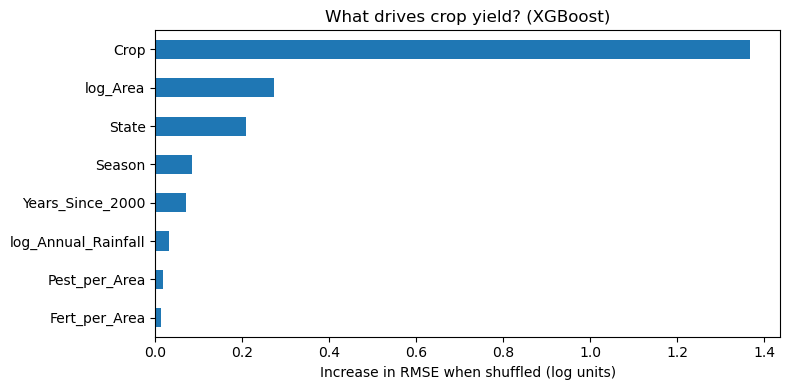

In [24]:
# Final model = the winner by validation
final_xgb = models["deeper (depth 8)"]

# Final scores
final_res = pd.DataFrame({
    "Train": evaluate(y_train, final_xgb.predict(X_train_p), k),
    "Test": evaluate(y_test, final_xgb.predict(X_test_p), k),
}).round(3)
print("=== FINAL XGBOOST (log space) ===")
print(final_res)

fin_back = np.expm1(final_xgb.predict(X_test_p))
print("\nTest R2 original units, all crops:        ",
      round(r2_score(yraw_test, fin_back), 3))
print("Test R2 original units, without Coconut:  ",
      round(r2_score(yraw_test[nc], fin_back[nc]), 3))

# Permutation importance on the ORIGINAL columns (grouped fairly)
rng = np.random.default_rng(42)
base_rmse = np.sqrt(mean_squared_error(y_test, final_xgb.predict(X_test_p)))
imp = {}
for col in num_feats + cat_feats:
    incr = []
    for _ in range(5):
        Xs = X_test.copy()
        Xs[col] = rng.permutation(Xs[col].values)   # shuffle one column
        p = final_xgb.predict(preprocessor.transform(Xs))
        incr.append(np.sqrt(mean_squared_error(y_test, p)) - base_rmse)
    imp[col] = np.mean(incr)

imp = pd.Series(imp).sort_values(ascending=False)
print("\n=== PERMUTATION IMPORTANCE (RMSE increase when shuffled) ===")
print(imp.round(3))

plt.figure(figsize=(8, 4))
imp.iloc[::-1].plot(kind="barh")
plt.xlabel("Increase in RMSE when shuffled (log units)")
plt.title("What drives crop yield? (XGBoost)")
plt.tight_layout()
plt.show()

> **Inference: final model performance**
>
> - **Test (log space):** R² 0.970, Adj R² 0.969, RMSE 0.209, MAE 0.123. Train R² 0.994.
> - **Typical error:** A log MAE of 0.123 is about 13% of a farm's yield, against about 33% for the linear baseline.
> - **Original units:** R² 0.966 for all crops and 0.904 without Coconut. The all-crops figure is flattered by Coconut's huge values, so the 0.904 is the fairer number.
> - **Train RMSE 0.093 vs 0.021 in the tuning table:** Not a contradiction: this cell scores all of `X_train`, including the 15% validation rows the model never trained on. The two figures blend to about 0.093.
> - **Did tuning help?:** Test RMSE is 0.209 against 0.208 for the first XGBoost. Tuning confirmed the configuration rather than improving it.

> **Inference: what drives crop yield (permutation importance)**
>
> - **Ranking (increase in test RMSE when shuffled):** `Crop` 1.367, `log_Area` 0.273, `State` 0.209, `Season` 0.084, `Years_Since_2000` 0.071, `log_Annual_Rainfall` 0.032, `Pest_per_Area` 0.017, `Fert_per_Area` 0.013.
> - **Chart:** The `Crop` bar is about 5 times the next one (`log_Area`) and about 100 times the fertilizer bar.
> - **State:** Third, even though its eta squared on its own was only 0.05. State matters mostly in combination with crop (the same crop yields differently across regions).
> - **Season:** Partly a proxy for crop, so some of its credit is shared with `Crop`.
> - **Rainfall, fertilizer and pesticide:** Low importance. This does not mean they do not matter agronomically: fertilizer and pesticide per unit of area are almost constant in this data (Section 4), leaving little variation to learn from.
> - **Caution:** Importance is a statement about this model on this dataset, not proof of cause. Correlated features share credit.

---

## Section 10: What-If Analysis
*Change one input for real test rows, re-predict, and compare the predicted yield.*

In [25]:
base = X_test.copy()
base_pred = final_xgb.predict(preprocessor.transform(base))

def what_if(change_fn, mask=None):
    """Change one thing for the affected rows; return avg % change in yield."""
    idx = mask if mask is not None else pd.Series(True, index=base.index)
    mod = change_fn(base.copy(), idx)
    new_pred = final_xgb.predict(preprocessor.transform(mod))
    # ratio of predicted yields: (1 + new) / (1 + old), from log predictions
    ratio = (np.expm1(new_pred) + 1) / (np.expm1(base_pred) + 1)
    r = ratio[idx.values]
    return (r.mean() - 1) * 100, (np.median(r) - 1) * 100, int(idx.sum())

g = np.log(1.2)   # +20% in log space
sc = {}
sc["Rainfall +20%"] = what_if(
    lambda d, i: d.assign(log_Annual_Rainfall=d["log_Annual_Rainfall"] + g))
sc["Fertilizer per ha +20%"] = what_if(
    lambda d, i: d.assign(Fert_per_Area=d["Fert_per_Area"] + g))
sc["Pesticide per ha +20%"] = what_if(
    lambda d, i: d.assign(Pest_per_Area=d["Pest_per_Area"] + g))
sc["Planted area +20%"] = what_if(
    lambda d, i: d.assign(log_Area=d["log_Area"] + g))
sc["5 years later"] = what_if(
    lambda d, i: d.assign(Years_Since_2000=d["Years_Since_2000"] + 5))
kh = base["Season"] == "Kharif"
sc["Kharif -> Rabi"] = what_if(
    lambda d, i: d.assign(Season=d["Season"].where(~i, "Rabi")), kh)

rec = pd.DataFrame(sc, index=["Mean_%_change", "Median_%_change", "Rows"]).T
rec["Rows"] = rec["Rows"].astype(int)
print(rec.round(1).sort_values("Median_%_change", ascending=False).to_string())

# Typical prediction error for context (as a % of yield, log MAE -> %)
print(f"\nFor scale: the model's typical error is about "
      f"{(np.exp(final_res.loc['MAE', 'Test']) - 1) * 100:.0f}% of a farm's yield")

                        Mean_%_change  Median_%_change  Rows
5 years later                     4.2              3.3  3480
Planted area +20%                 1.3              0.4  3480
Fertilizer per ha +20%            1.3              0.0  3480
Rainfall +20%                     0.3              0.0  3480
Pesticide per ha +20%             0.2              0.0  3480
Kharif -> Rabi                   -2.5             -2.4  1643

For scale: the model's typical error is about 13% of a farm's yield


> **Inference: single-input changes move predicted yield by only a few percent**
>
> - **Results (mean / median % change in predicted yield):** 5 years later +4.2 / +3.3; planted area +20% +1.3 / +0.4; fertilizer per unit of area +20% +1.3 / 0.0; rainfall +20% +0.3 / 0.0; pesticide per unit of area +20% +0.2 / 0.0; Kharif → Rabi −2.5 / −2.4 (1,643 rows).
> - **Scale:** Every effect is small relative to the model's typical error of about 13% per row. Averages over thousands of rows are more reliable than any single prediction.
> - **Median 0.0%:** For fertilizer, pesticide and rainfall the median is exactly zero, so for most rows the change does not cross any tree split. The mean is pulled up by a minority of rows.
> - **Time:** +3.3% for five years is consistent with the upward drift seen in Section 3. It cannot be extended beyond the observed years.
> - **Season:** Kharif → Rabi is a small drop, but season is partly a proxy for crop, so the comparison is fragile.
> - **Takeaway:** In this dataset, crop and region matter far more than marginal changes in inputs. This is a statement about the data (which has near-constant per-area inputs), not about agronomy in general.

> **Issue: limitations of the what-if analysis**
>
> - **Not causal:** These are model predictions. Changing one feature while holding the rest fixed can create combinations that never occur in reality.
> - **Not additive:** The effects of several changes will not add up because of interactions.
> - **Units:** The unit of `Yield` is not stated, so percentage changes are the safe way to read these results.

---

## Section 11: Save the Final Pipeline
*Bundle preprocessing and model so new data can be scored from raw columns.*

In [26]:
import joblib

# Bundle preprocessing + model
final_pipeline = Pipeline([("prep", preprocessor), ("model", final_xgb)])
joblib.dump(final_pipeline, "crop_yield_xgb.joblib")

# Helper: raw columns in, predicted Yield out
def predict_yield(raw):
    """raw needs: Year, State, Crop, Season, Area, Annual_Rainfall,
    Fertilizer, Pesticide (blanks are allowed)."""
    d = raw.copy()
    d["log_Area"] = np.log1p(d["Area"])
    d["log_Annual_Rainfall"] = np.log1p(d["Annual_Rainfall"])
    d["Fert_per_Area"] = np.log1p(d["Fertilizer"]) - d["log_Area"]
    d["Pest_per_Area"] = np.log1p(d["Pesticide"]) - d["log_Area"]
    d["Years_Since_2000"] = d["Year"] - 2000
    model = joblib.load("crop_yield_xgb.joblib")
    log_pred = model.predict(d[num_feats + cat_feats])
    return np.expm1(log_pred)            # back to original units

# Test: reload and predict 3 raw rows, compare to earlier predictions
sample = df.loc[X_test.index[:3], ["Year", "State", "Crop", "Season", "Area",
                                   "Annual_Rainfall", "Fertilizer", "Pesticide"]]
new_pred = predict_yield(sample)
old_pred = np.expm1(final_xgb.predict(X_test_p[:3]))

print("Max difference vs earlier predictions:",
      np.abs(new_pred - old_pred).max())
print("\nPredicted yield:", new_pred.round(2))
print("Actual yield:   ", yraw_test.values[:3].round(2))

# Full-test check through the saved pipeline (log space)
loaded = joblib.load("crop_yield_xgb.joblib")
print("\nTest RMSE from reloaded pipeline (log):",
      round(np.sqrt(mean_squared_error(y_test, loaded.predict(X_test))), 3))

Max difference vs earlier predictions: 0.0

Predicted yield: [8.85 0.19 2.99]
Actual yield:    [9.54 0.23 2.94]

Test RMSE from reloaded pipeline (log): 0.209


> **Inference: saved pipeline reproduces the results exactly**
>
> - **Check:** Maximum difference from the earlier predictions is 0.0, and the reloaded pipeline gives test RMSE 0.209 (log), the same as before.
> - **Sample:** Predicted 8.85, 0.19 and 2.99 against actual 9.54, 0.23 and 2.94 (about −7%, −17% and +2%). The same scale of error as the typical 13%.
> - **Usage:** `predict_yield(raw)` needs `Year, State, Crop, Season, Area, Annual_Rainfall, Fertilizer, Pesticide`. Blanks are allowed and `Production` is not needed.

> **Issue: deployment cautions**
>
> - **Unseen categories:** The encoder is set to ignore unknown crops or states, so a new crop is scored as the reference level without warning. Check inputs against the 62 known crops and 31 known states.
> - **Versions:** The `.joblib` file depends on the scikit-learn and xgboost versions used to create it; pin them.
> - **Training data:** The model inside was fitted on 85% of the training rows. Refit on all training data for production.

---

## Section 12: Results, Recommendations & Conclusion
*Final model comparison and what to do with it.*

### Model comparison (test set)

| Model | R² (log) | RMSE (log) | MAE (log) | R² original units, no Coconut | Verdict |
|---|---|---|---|---|---|
| Linear Regression | 0.864 | 0.445 | 0.288 | 0.694 | Baseline; assumptions fail |
| Ridge | 0.864 | 0.446 | 0.288 | 0.694 | Same as linear |
| Lasso | 0.864 | 0.445 | 0.288 | 0.691 | Same as linear |
| Random Forest | 0.967 | 0.219 | 0.123 | 0.889 | Large gain; overfit gap |
| XGBoost (first fit) | 0.970 | 0.208 | 0.124 | 0.908 | Best R² and RMSE |
| **XGBoost (final, depth 8)** | **0.970** | **0.209** | **0.123** | **0.904** | **Selected: validated configuration** |

> **Decision: key conclusions**
>
> - **Crop identity drives yield.** Eta squared 0.83, the biggest coefficients in every linear model, and permutation importance about 5 times the next feature.
> - **Non-linear models are worth it.** Moving from linear to boosted trees takes R² from 0.864 to 0.970 and halves RMSE, because the effect of area, state and year differs by crop.
> - **Typical error is about 13% of yield** (33% for the linear model), but heavy tails remain. The model is weakest on high-yield, high-variance crops (Coconut, Jute, Ginger, Sugarcane, Onion, Banana).
> - **Marginal input changes have small predicted effects** (a few percent), well below the per-row error.
> - **Tuning confirmed rather than improved.** Depth 8 won on validation and test, but the first XGBoost was equally good (RMSE 0.208 vs 0.209).

> **Decision: recommendations**
>
> - Use the model for crop- and region-level yield benchmarking and planning, not for single-farm decisions.
> - Report errors in relative or log terms, and report Coconut separately.
> - Do not use this model to prescribe fertilizer, pesticide or irrigation changes. The inputs here carry little independent information (per-area use is almost constant).
> - Resolve the data issues before relying on the numbers: confirm yield units (especially Coconut), reconcile `Yield` with `Production / Area` (over half the rows disagree by more than 1%), explain the 2020 spike, and explain the group of rows with very low fertilizer per unit of area.
> - If agronomic questions matter, collect measured per-farm inputs instead of the current near-constant per-area values.

> **Issue: limitations and next steps**
>
> - **Limitations:** random (not time-based) split; one validation split used for tuning; final model fitted on 85% of training rows; what-if results are predictions, not causal effects; target units not stated; aggregate rows such as `Oilseeds total` are modelled as if they were crops; no prediction intervals.
> - **Next steps:** time-based validation (train on early years, test on later ones); cross-validated tuning with grouped folds by state or year; prediction intervals (quantile or conformal); SHAP explanations per prediction; separate treatment of Coconut; richer weather and soil features; refit on all training data and wrap in a small scoring service.

### Using the saved pipeline

```python
import joblib
import numpy as np
import pandas as pd

model = joblib.load("crop_yield_xgb.joblib")

# Use predict_yield(raw) from Section 11, which builds the log features first.
# Required raw columns: Year, State, Crop, Season, Area,
# Annual_Rainfall, Fertilizer, Pesticide (blanks allowed).
# predicted_yield = predict_yield(new_rows)
```